# 07 — Klasifikasi SVM Enam Kelas: Perbandingan Faktorial 2×3 dengan Evaluasi Ketat *Fold-Aware & Validation-Blind* (`v3`)

## Ringkasan utama

Notebook ini memfinalisasi **klasifikasi tingkat citra (*image-level*) enam kelas** pada dataset EBHI-SEG menggunakan *Support Vector Machine* (SVM) untuk membandingkan desain faktorial lengkap **2×3** (`otsu_M0`, `otsu_M1`, `otsu_M2`, `k4_M0`, `k4_M1`, `k4_M2`) bersama **Set A bersama** (10 fitur *appearance* independen segmentasi) dan analisis sensitivitas sekunder `A_seg`/`C_seg` pada `k4_M0`.

### Lima lapisan eksperimen yang dipisahkan secara eksplisit
1. **Tahap 01–05b (`otsu` & `k4` segmentasi):** pengembangan segmentasi dan diagnostik kasus pada `train`/`val` (`results/*_morph_val.csv`).
2. **Tahap 07 `v1` (`results/classification/`, `models/svm_*.json`):** eksperimen awal 4 metode (`otsu_M0`, `otsu_M2`, `k4_M0`, `k4_M1`) yang hiperparameternya disetel berbasis `val` pada `k4_M0_C`. Dipertahankan utuh sebagai referensi historis.
3. **Tahap 08 historis (`results/test/`, `notebooks/08_final_test_evaluation.ipynb`):** evaluasi satu kali *held-out test* milik protokol `v1`. **Tidak pernah dijalankan ulang maupun diakses** pada eksperimen `v2`/`v3`.
4. **Tahap 07 `v2` (`results/classification_2x3/`, `models/cv_2x3/`):** perluasan 2×3 penuh dengan pencarian grid 32 kandidat identik per model dan `StandardScaler` di dalam fold *5-fold StratifiedGroupKFold*, tetapi memakai tabel fitur global dengan polaritas Otsu dan klastering/pemetaan `k4` yang sebelumnya dipasang pada `train` penuh (*fixed-upstream CV*).
5. **Tahap 07 `v3` — kanonik final (`2x3-strict`, `results/classification_2x3_strict/`, `models/cv_2x3_strict/`):** audit kebocoran dan perbaikan metodologis lengkap:
   - Polaritas Otsu (`"dark"` vs `"bright"`) dan model `MiniBatchKMeans(k=4)` beserta pemetaan klaster terawasi (`foreground_rate >= 0.50`) serta `StandardScaler` dipasang ulang **di dalam tiap fold latih *5-fold StratifiedGroupKFold*** (`1.535` citra, `247` grup).
   - Pencarian grid **32 spesifikasi identik per kombinasi** (**480 baris** lintas **15 kombinasi**) bersifat ***validation-blind* secara struktural** (`0` kolom `val_*` pada `svm_2x3_strict_grid_results.csv`).
   - Setiap model terpilih (`cv_selection_key_for_svm`) dilatih ulang **sekali** pada seluruh `train`, lalu dievaluasi **sekali** pada `val` (`372` citra, `53` grup) lengkap dengan **bootstrap berpasangan terblok grup (*53 val groups*, `B = 2.000`, `seed = 42`)**.


## Konteks ilmiah, audit kebocoran *upstream*, dan kontrak seleksi

- **Otoritas kohort:** `split_manifest.csv` diverifikasi secara *raw-byte* (`ceeba8e2...`). Karena terdapat `74` `group_id` multi-kategori, pemodelan dilakukan *image-level* namun pembagian CV maupun `train`/`val` tetap *group-disjoint*.
- **Independensi Set A:** Set A (10 fitur CIE Lab + GLCM seluruh piksel) identik di seluruh konfigurasi dan dievaluasi satu kali sebagai **`shared_appearance A`**.
- **Ketergantungan *upstream* pada `otsu` vs `k4`:** dalam setiap fold `5-fold StratifiedGroupKFold`, `otsu` mengecek polaritas `"dark"` vs `"bright"` pada *ground truth* `fold_train` (`5/5` fold memilih `"dark"` dengan margin Dice $\ge +0,2841$), sedangkan `k4` melatih `MiniBatchKMeans(k=4)` baru pada piksel `fold_train` lalu memetakan klaster terhadap *ground truth* `fold_train` (`rate >= 0,50`).
- **Aturan seleksi deterministik (`cv_selection_key_for_svm`):** `cv_macro_f1` OOF (4 desimal) $\rightarrow$ `cv_balanced_accuracy` (4 desimal) $\rightarrow$ `cv_accuracy` (4 desimal) $\rightarrow$ `cv_fold_macro_f1_mean` (4 desimal) $\rightarrow$ `linear > rbf` $\rightarrow$ `-C` $\rightarrow$ `gamma` lebih lebar $\rightarrow$ `none > balanced`.


In [1]:
%matplotlib inline

import json
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

from ebhi_dip import (
    CLASSIFICATION_2X3_DIR_REL,
    CLASSIFICATION_2X3_STRICT_DIR_REL,
    COMPARISON_2X3_METHODS,
    DECISION_PARITY_ATOL,
    EXPECTED_CATEGORIES,
    MODELS_CV_2X3_STRICT_DIR_REL,
    PRIMARY_FEATURE_METHOD,
    SHARED_APPEARANCE_METHOD,
    apply_standard_scaler,
    classification_metrics,
    configure_notebook_style,
    confusion_matrix_table,
    cv_selection_key_for_svm,
    feature_columns_for_set,
    find_project_root,
    finish_figure,
    fit_standard_scaler,
    fit_svm_model,
    load_classification_feature_frame,
    load_shared_appearance_frame,
    load_svm_artifact,
    method_label,
    predict_from_svm_artifact,
    sha256_bytes,
    verify_frozen_split,
    verify_svm_artifact_parity,
)

PROJECT_ROOT_OVERRIDE = None
EXPORT_FIGURES = False
PRIMARY_METHOD = PRIMARY_FEATURE_METHOD
FEATURE_METHODS = COMPARISON_2X3_METHODS

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
CLS_STRICT_DIR = ROOT / CLASSIFICATION_2X3_STRICT_DIR_REL
CLS_V2_DIR = ROOT / CLASSIFICATION_2X3_DIR_REL
CLS_LEGACY_DIR = ROOT / "results/classification"
FEATURE_DIR = ROOT / "results/features"
MODELS_STRICT_DIR = ROOT / MODELS_CV_2X3_STRICT_DIR_REL
configure_notebook_style()

# Verify hashes of all preserved upstream, v1, historical Stage 08 metadata, v2, and v3 artifacts
# without touching or decoding test-split predictions/labels.
protected_files = {
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
    "seg_selection_cfg": ROOT / "configs/segmentation_selection.json",
    "hist_test_manifest": ROOT / "results/test/final_test_manifest.json",
    "feature_manifest_2x3": FEATURE_DIR / "feature_manifest_2x3.json",
    "diagnostics_2x3": FEATURE_DIR / "morphology_diagnostics_2x3.csv",
    "appearance": FEATURE_DIR / "appearance.csv",
    "segmented_manifest": FEATURE_DIR / f"feature_manifest_segmented_{PRIMARY_METHOD}.json",
    "segmented_features": FEATURE_DIR / f"features_{PRIMARY_METHOD}_segmented.csv",
    "v1_cls_manifest": CLS_LEGACY_DIR / "classification_manifest.json",
    "v1_cls_summary": CLS_LEGACY_DIR / "svm_selected_summary.csv",
    "v1_cls_comp": CLS_LEGACY_DIR / "svm_comparator_sensitivity.csv",
    "v2_cls_manifest": CLS_V2_DIR / "classification_2x3_manifest.json",
    "v2_cls_summary": CLS_V2_DIR / "svm_2x3_selected_summary.csv",
    "v3_audit": CLS_STRICT_DIR / "fold_upstream_audit.json",
    "v3_manifest": CLS_STRICT_DIR / "classification_2x3_strict_manifest.json",
    "v3_grid": CLS_STRICT_DIR / "svm_2x3_strict_grid_results.csv",
    "v3_summary": CLS_STRICT_DIR / "svm_2x3_strict_selected_summary.csv",
    "v3_per_cat": CLS_STRICT_DIR / "svm_2x3_strict_per_category_val.csv",
    "v3_seg_cls": CLS_STRICT_DIR / "svm_2x3_strict_seg_vs_cls.csv",
    "v3_val_pred": CLS_STRICT_DIR / "svm_2x3_strict_val_predictions.csv",
    "v3_boot_models": CLS_STRICT_DIR / "svm_2x3_strict_val_bootstrap_models.csv",
    "v3_boot_contrasts": CLS_STRICT_DIR / "svm_2x3_strict_val_paired_contrasts.csv",
    "v3_vs_v2": CLS_STRICT_DIR / "svm_2x3_strict_vs_fixed_upstream.csv",
}
protected_files.update({f"features_{m}": FEATURE_DIR / f"features_{m}.csv" for m in FEATURE_METHODS})
input_hashes_before = {name: sha256_bytes(path) for name, path in protected_files.items()}

display(
    pd.DataFrame(
        {
            "komponen": [
                "Python / NumPy / pandas / sklearn",
                "Protokol aktif (kanonik)",
                "Konfigurasi 2x3",
                "Seleksi hiperparameter",
                "Bootstrap validasi",
                "Akses held-out test di v2/v3",
            ],
            "nilai": [
                f"{platform.python_version()} / {np.__version__} / {pd.__version__} / {sklearn.__version__}",
                "v3 (2x3-strict: fold-aware upstream + val-blind grid)",
                ", ".join(FEATURE_METHODS),
                "5-fold StratifiedGroupKFold Macro-F1 pada train (0 kolom val_* di grid)",
                "53 validation groups, B=2.000 resamples (seed=42)",
                "DILARANG (test_images_touched_in_2x3_strict == 0)",
            ],
        }
    )
)


,komponen,nilai
0,Python / NumPy / pandas / sklearn,3.14.0 / 2.5.4 / 3.1.1 / 1.9.1
1,Protokol aktif (kanonik),v3 (2x3-strict: fold-aware upstream + val-blin...
2,Konfigurasi 2x3,"otsu_M0, otsu_M1, otsu_M2, k4_M0, k4_M1, k4_M2"
3,Seleksi hiperparameter,5-fold StratifiedGroupKFold Macro-F1 pada trai...
4,Bootstrap validasi,"53 validation groups, B=2.000 resamples (seed=42)"
5,Akses held-out test di v2/v3,DILARANG (test_images_touched_in_2x3_strict == 0)


## 1. Verifikasi isolasi *split*, integritas *validation-blind grid*, dan keseimbangan kelas

Sel ini memverifikasi bahwa:
1. Tabel kandidat grid `svm_2x3_strict_grid_results.csv` (`480` baris = `15` model $\times$ `32` spesifikasi) **tidak mengandung satu pun kolom `val_*`** (*strictly validation-blind*).
2. Seleksi CV deterministik `cv_selection_key_for_svm` merekonstruksi pilihan terbaik tepat sama untuk seluruh `15` kombinasi.
3. Subset `test` (`319` citra) sama sekali tidak dibuka pada studi `2x3-strict`.


In [2]:
cls_manifest = json.loads(protected_files["v3_manifest"].read_text(encoding="utf-8"))
audit_payload = json.loads(protected_files["v3_audit"].read_text(encoding="utf-8"))
grid_df = pd.read_csv(protected_files["v3_grid"])
summary_df = pd.read_csv(protected_files["v3_summary"])
per_cat_df = pd.read_csv(protected_files["v3_per_cat"])
seg_cls_df = pd.read_csv(protected_files["v3_seg_cls"])
val_pred_df = pd.read_csv(protected_files["v3_val_pred"])
boot_models_df = pd.read_csv(protected_files["v3_boot_models"])
contrasts_df = pd.read_csv(protected_files["v3_boot_contrasts"])
vs_v2_df = pd.read_csv(protected_files["v3_vs_v2"])

train_app, val_app, loaded_sha = load_shared_appearance_frame(ROOT)
assert loaded_sha == SPLIT_SHA == cls_manifest["split_sha256"] == audit_payload["split_sha256"]
assert cls_manifest["cohort_counts"]["test_images_touched_in_2x3_strict"] == 0
assert cls_manifest["cohort_counts"]["test_labels_accessed_in_2x3_strict"] is False
assert set(val_pred_df["split"]) == {"val"}
assert len(train_app) == 1535 and len(val_app) == 372

# Structural validation-blind check: grid search CSV must carry ZERO val_* columns
val_cols_in_grid = [col for col in grid_df.columns if str(col).startswith("val_")]
assert len(val_cols_in_grid) == 0, f"Unexpected val_* columns in strict grid: {val_cols_in_grid}"
assert len(grid_df) == 480 and grid_df.groupby(["method", "feature_set"]).ngroups == 15

for (method, fset), grp in grid_df.groupby(["method", "feature_set"], sort=False):
    sel_row = grp.loc[grp["is_selected_best"]].iloc[0]
    re_selected = max(grp.to_dict("records"), key=cv_selection_key_for_svm)
    assert (
        str(sel_row["kernel"]),
        str(sel_row["class_weight"]),
        float(sel_row["C"]),
        str(sel_row["gamma"]),
    ) == (
        str(re_selected["kernel"]),
        str(re_selected["class_weight"]),
        float(re_selected["C"]),
        str(re_selected["gamma"]),
    )

class_balance = pd.DataFrame(
    {
        "train_images": train_app["category"].value_counts().reindex(EXPECTED_CATEGORIES),
        "train_groups": train_app.groupby("category", observed=True)["group_id"].nunique().reindex(EXPECTED_CATEGORIES),
        "val_images": val_app["category"].value_counts().reindex(EXPECTED_CATEGORIES),
        "val_groups": val_app.groupby("category", observed=True)["group_id"].nunique().reindex(EXPECTED_CATEGORIES),
    }
)
class_balance["train_share_pct"] = 100.0 * class_balance["train_images"] / len(train_app)
class_balance["val_share_pct"] = 100.0 * class_balance["val_images"] / len(val_app)
class_balance.loc["TOTAL"] = [
    int(class_balance["train_images"].sum()),
    int(train_app["group_id"].nunique()),
    int(class_balance["val_images"].sum()),
    int(val_app["group_id"].nunique()),
    100.0,
    100.0,
]

display(
    class_balance.style.format(
        {
            "train_images": "{:.0f}",
            "train_groups": "{:.0f}",
            "val_images": "{:.0f}",
            "val_groups": "{:.0f}",
            "train_share_pct": "{:.2f}%",
            "val_share_pct": "{:.2f}%",
        }
    )
)
print(
    f"Terverifikasi: grid ketat 480 kandidat (15 x 32) mengandung {len(val_cols_in_grid)} kolom val_*; "
    f"seleksi CV deterministik cocok 15/15; 0 citra test disentuh."
)


,train_images,train_groups,val_images,val_groups,train_share_pct,val_share_pct
category,,,,,,
Adenocarcinoma,540,75,131,15,35.18%,35.22%
High-grade IN,131,28,20,5,8.53%,5.38%
Low-grade IN,444,101,107,21,28.93%,28.76%
Normal,54,11,10,3,3.52%,2.69%
Polyp,324,81,96,21,21.11%,25.81%
Serrated adenoma,42,10,8,2,2.74%,2.15%
TOTAL,1535,247,372,53,100.00%,100.00%


Terverifikasi: grid ketat 480 kandidat (15 x 32) mengandung 0 kolom val_*; seleksi CV deterministik cocok 15/15; 0 citra test disentuh.


### Temuan 1 — struktur validasi berisiko varians tinggi pada kelas langka

- Tiga kelas mayoritas (`Adenocarcinoma`, `Low-grade IN`, `Polyp`) mencakup **85,21% `train`** dan **89,78% `val`**.
- Sebaliknya, pada `val` (`53` grup total), **`Serrated adenoma`** hanya berada pada **`2` grup (`8` citra)** dan **`Normal`** pada **`3` grup (`10` citra)**, sehingga bootstrap grup validasi mencatat keberadaan serentak ke-6 kelas pada **`82,3%`** dari `2.000` penarikan ulang (`all_6_categories_present_frac = 0.823`). Karena itu, klaim komparatif harus ditopang oleh interval kepercayaan *group-blocked bootstrap* selain nilai titik.


## 2. Audit kebocoran *upstream* per fold dan sensitivitas protokol `v2` (*fixed*) vs `v3` (*strict*)

Sel ini memeriksa langsung `fold_upstream_audit.json` dan `svm_2x3_strict_vs_fixed_upstream.csv` untuk mengukur:
1. Apakah polaritas Otsu berubah antar-fold ketika diseleksi ulang hanya memakai `fold_train`?
2. Seberapa besar pergeseran *centroid* Lab K-Means (`k=4`), pemetaan klaster terawasi, dan kesepakatan piksel masker `k4_M0` saat dilatih murni per fold?
3. Bagaimana dampaknya terhadap spesifikasi terpilih dan Macro-F1 pada `v3` vs `v2`?


,fold,train_imgs,val_imgs,train_grps,val_grps,group_disjoint,otsu_polarity,otsu_margin_dice,k4_fg_clusters,k4_min_fg_rate,k4_max_bg_rate,k4_center_L2_vs_full,k4_M0_val_px_agree,k4_M0_val_iou_vs_full,k4_M0_val_iou_min
0,0,1232,303,198,49,True,dark,+0.2841,"[0, 2, 3]",0.5509,0.3948,2.88,0.9897,0.9873,0.9354
1,1,1226,309,198,49,True,dark,+0.2952,"[0, 2, 3]",0.5331,0.3938,3.69,0.9871,0.9842,0.8704
2,2,1231,304,197,50,True,dark,+0.2937,"[0, 1, 3]",0.5462,0.4003,1.48,0.9958,0.9949,0.9637
3,3,1224,311,201,46,True,dark,+0.2964,"[0, 1, 3]",0.5462,0.3938,8.46,0.9701,0.9601,0.3024
4,4,1227,308,194,53,True,dark,+0.2882,"[1, 2, 3]",0.5427,0.3956,5.53,0.9783,0.9732,0.8049


Otsu 5/5 fold invariant='dark': True | Worker parity vs canonical Otsu CSVs: {'otsu_M0': 2.220446049250313e-16, 'otsu_M1': 0.0, 'otsu_M2': 1.1102230246251565e-16}


,method,feature_set,fixed_v2_spec,strict_v3_spec,identical_selected_spec,fixed_v2_cv_macro_f1,strict_v3_cv_macro_f1,delta_cv_macro_f1_v3_minus_v2,fixed_v2_val_macro_f1,strict_v3_val_macro_f1,delta_val_macro_f1_v3_minus_v2,delta_val_macro_f1_ci95_low,delta_val_macro_f1_ci95_high
0,shared_appearance,A,rbf none C=10 g=scale,rbf none C=10 g=scale,True,0.3346,0.3346,+0.0000,0.3140,0.3140,+0.0000,+0.0000,+0.0000
1,otsu_M0,B,rbf balanced C=10 g=0.01,rbf balanced C=10 g=0.01,True,0.4126,0.4126,+0.0000,0.3280,0.3280,+0.0000,+0.0000,+0.0000
2,otsu_M0,C,linear none C=3 g=scale,linear none C=3 g=scale,True,0.4642,0.4642,+0.0000,0.4058,0.4058,+0.0000,+0.0000,+0.0000
3,otsu_M1,B,rbf balanced C=10 g=0.01,rbf balanced C=10 g=0.01,True,0.3789,0.3789,+0.0000,0.3033,0.3033,+0.0000,+0.0000,+0.0000
4,otsu_M1,C,rbf balanced C=3 g=0.01,rbf balanced C=3 g=0.01,True,0.4481,0.4481,+0.0000,0.3470,0.3470,+0.0000,+0.0000,+0.0000
5,otsu_M2,B,rbf balanced C=10 g=0.01,rbf balanced C=10 g=0.01,True,0.4077,0.4077,+0.0000,0.3055,0.3055,+0.0000,+0.0000,+0.0000
6,otsu_M2,C,rbf balanced C=3 g=0.01,rbf balanced C=3 g=0.01,True,0.4622,0.4622,+0.0000,0.3462,0.3462,+0.0000,+0.0000,+0.0000
7,k4_M0,B,rbf balanced C=3 g=scale,rbf balanced C=10 g=scale,False,0.2937,0.2744,-0.0192,0.2287,0.2490,+0.0203,-0.0029,+0.0478
8,k4_M0,C,rbf balanced C=10 g=0.01,rbf balanced C=3 g=scale,False,0.3774,0.3707,-0.0067,0.3362,0.3386,+0.0024,-0.0299,+0.0360
9,k4_M1,B,rbf balanced C=10 g=scale,rbf balanced C=10 g=0.1,False,0.2580,0.2797,+0.0218,0.2276,0.2311,+0.0035,-0.0241,+0.0337


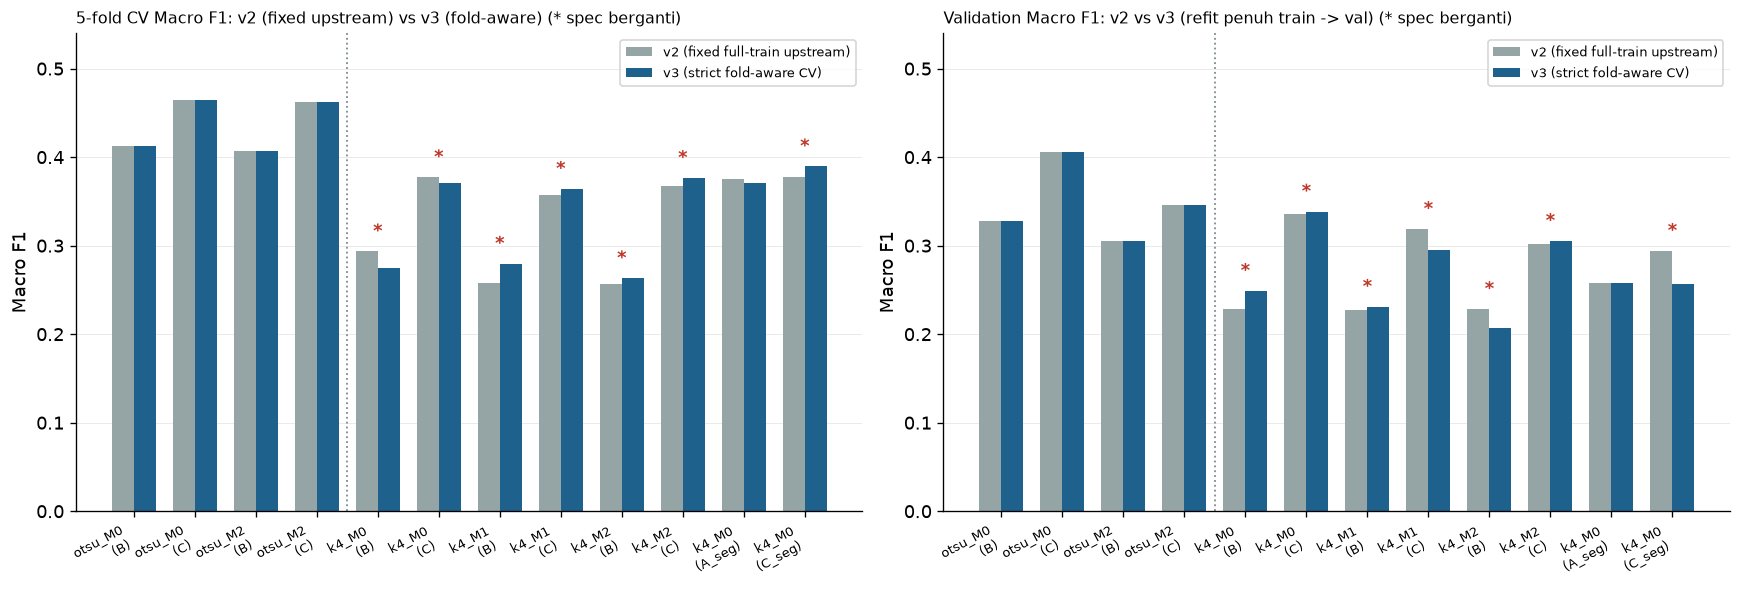

In [3]:
fold_rows = []
for f in audit_payload["folds"]:
    fold_rows.append(
        {
            "fold": int(f["fold"]),
            "train_imgs": int(f["fold_train_images"]),
            "val_imgs": int(f["fold_val_images"]),
            "train_grps": int(f["fold_train_groups"]),
            "val_grps": int(f["fold_val_groups"]),
            "group_disjoint": bool(f["group_id_disjoint"]),
            "otsu_polarity": f["otsu_polarity_fit"]["chosen_polarity"],
            "otsu_margin_dice": float(f["otsu_polarity_fit"]["margin_dark_minus_bright"]),
            "k4_fg_clusters": str(f["k4_fit"]["foreground_clusters"]),
            "k4_min_fg_rate": min(float(x) for x in f["k4_fit"]["cluster_reference_foreground_rates"] if float(x) >= 0.5),
            "k4_max_bg_rate": max(float(x) for x in f["k4_fit"]["cluster_reference_foreground_rates"] if float(x) < 0.5),
            "k4_center_L2_vs_full": float(f["k4_cluster_center_mean_l2_vs_full_train"]),
            "k4_M0_val_px_agree": float(f["k4_m0_val_fold_pixel_agreement_mean"]),
            "k4_M0_val_iou_vs_full": float(f["k4_m0_val_fold_iou_vs_full_train_mean"]),
            "k4_M0_val_iou_min": float(f["k4_m0_val_fold_iou_vs_full_train_min"]),
        }
    )
fold_audit_df = pd.DataFrame(fold_rows)
display(
    fold_audit_df.style.format(
        {
            "otsu_margin_dice": "{:+.4f}",
            "k4_min_fg_rate": "{:.4f}",
            "k4_max_bg_rate": "{:.4f}",
            "k4_center_L2_vs_full": "{:.2f}",
            "k4_M0_val_px_agree": "{:.4f}",
            "k4_M0_val_iou_vs_full": "{:.4f}",
            "k4_M0_val_iou_min": "{:.4f}",
        }
    )
)
print(
    f"Otsu 5/5 fold invariant='dark': {audit_payload['otsu_fold_invariance_all_dark']} | "
    f"Worker parity vs canonical Otsu CSVs: {audit_payload['otsu_worker_vs_canonical_max_abs_diff']}"
)

display(
    vs_v2_df[
        [
            "method",
            "feature_set",
            "fixed_v2_spec",
            "strict_v3_spec",
            "identical_selected_spec",
            "fixed_v2_cv_macro_f1",
            "strict_v3_cv_macro_f1",
            "delta_cv_macro_f1_v3_minus_v2",
            "fixed_v2_val_macro_f1",
            "strict_v3_val_macro_f1",
            "delta_val_macro_f1_v3_minus_v2",
            "delta_val_macro_f1_ci95_low",
            "delta_val_macro_f1_ci95_high",
        ]
    ].style.format(
        {
            "fixed_v2_cv_macro_f1": "{:.4f}",
            "strict_v3_cv_macro_f1": "{:.4f}",
            "delta_cv_macro_f1_v3_minus_v2": "{:+.4f}",
            "fixed_v2_val_macro_f1": "{:.4f}",
            "strict_v3_val_macro_f1": "{:.4f}",
            "delta_val_macro_f1_v3_minus_v2": "{:+.4f}",
            "delta_val_macro_f1_ci95_low": "{:+.4f}",
            "delta_val_macro_f1_ci95_high": "{:+.4f}",
        }
    )
)

# Visual summary of v2 (fixed upstream) vs v3 (strict fold-aware) CV & Val Macro-F1 across k4 models vs Otsu
fig_v, axes_v = plt.subplots(1, 2, figsize=(14.4, 4.8), layout="constrained")
cmp_models = vs_v2_df.loc[vs_v2_df["method"].isin(["otsu_M0", "otsu_M2", "k4_M0", "k4_M1", "k4_M2"])].copy()
labels_v = [f"{r['method']}\n({r['feature_set']})" for _, r in cmp_models.iterrows()]
x_v = np.arange(len(cmp_models))
bw_v = 0.36

for ax, c_v2, c_v3, title in [
    (axes_v[0], "fixed_v2_cv_macro_f1", "strict_v3_cv_macro_f1", "5-fold CV Macro F1: v2 (fixed upstream) vs v3 (fold-aware)"),
    (axes_v[1], "fixed_v2_val_macro_f1", "strict_v3_val_macro_f1", "Validation Macro F1: v2 vs v3 (refit penuh train -> val)"),
]:
    v2_vals = cmp_models[c_v2].to_numpy(dtype=float)
    v3_vals = cmp_models[c_v3].to_numpy(dtype=float)
    b1 = ax.bar(x_v - bw_v / 2, v2_vals, width=bw_v, color="#95A5A6", label="v2 (fixed full-train upstream)")
    b2 = ax.bar(x_v + bw_v / 2, v3_vals, width=bw_v, color="#1F618D", label="v3 (strict fold-aware CV)")
    for idx_i, (r_s, v2_y, v3_y) in enumerate(zip(cmp_models["identical_selected_spec"], v2_vals, v3_vals)):
        if not bool(r_s):
            ax.text(x_v[idx_i], max(v2_y, v3_y) + 0.012, "*", ha="center", va="bottom", fontsize=11, color="#C0392B", fontweight="bold")
    ax.axvline(3.5, color="#7F8C8D", linestyle=":", linewidth=1.1)
    ax.set_xticks(x_v, labels_v, rotation=28, ha="right", fontsize=7.8)
    ax.set_ylim(0.0, 0.54)
    ax.set_ylabel("Macro F1")
    ax.set_title(title + " (* spec berganti)", loc="left", fontsize=9.8)
    ax.legend(frameon=True, fontsize=8.0, loc="upper right")
    ax.grid(axis="y", color="#EAEAEA", linewidth=0.6)

finish_figure(
    fig_v,
    export_path=(ROOT / "reports/figures/07_2x3_strict_vs_fixed_upstream.png") if EXPORT_FIGURES else None,
)


### Temuan 2 — kontras stabilitas *upstream*: Otsu invarian vs `k4` sensitif antar-fold

- **Keluarga Otsu (`otsu_M0..M2`) invarian 5/5 fold:** polaritas `"dark"` unggul meyakinkan atas `"bright"` pada setiap fold `fold_train` (margin Dice **`+0,2841` hingga `+0,2952`**) dan paritas fitur *worker* tepat identik hingga **`<= 2,22e-16`**. Seluruh `6` model Otsu dan `Shared Set A` tetap sama persis antara `v2` dan `v3` (`delta = 0,0000`).
- **Keluarga K-Means (`k4_M0..M2`) mengalami pergeseran *upstream* nyata per fold:**
  - Jarak L2 rata-rata *centroid* `k4` per fold terhadap model *full-train* berkisar **`1,48` hingga `8,46` satuan Lab**, dengan klaster batas merah muda mencatat *foreground rate* **`0,5331–0,5509`** di dekat ambang `0,50`.
  - Akibatnya, IoU masker `k4_M0` *fold-val* terhadap masker *full-train* rata-rata **`0,9601–0,9949`** namun pada citra sensitif di Fold 3 turun hingga **`0,3024`**.
  - Ketika kebocoran *upstream* dieliminasi pada **`v3`**, **`6 dari 7` model `k4`** berubah hiperparameter CV-nya (`k4_M0_{B,C}`, `k4_M1_{B,C}`, `k4_M2_{B,C}`, dan `k4_M0_C_seg`), dan **ketujuh model `k4` berubah skor CV Macro-F1**-nya (misalnya `k4_M0_B` turun `0,2937 -> 0,2744`; `k4_M0_C_seg` naik di CV `0,3777 -> 0,3897` namun turun di Val `0,2942 -> 0,2572`). Ini menegaskan bahwa *fixed-upstream CV* (`v2`) tidak boleh diklaim bebas kebocoran untuk klastering/pemetaan terawasi `k4`.


## 3. Hasil lengkap `2x3-strict` (`v3`) dan interval kepercayaan bootstrap 53 grup validasi

Tabel pertama menyajikan seluruh `15` model terpilih `cv_selected` (`strict` fold-aware CV & *val-blind* grid) beserta **95% *group-blocked bootstrap CI*** (`B = 2.000`, `53` grup `val`), sedangkan Tabel kedua meringkas **`15` kontras berpasangan `strict_2x3`** beserta probabilitas empiris $P(\Delta > 0)$.


,track,method,feature_set,kernel,class_weight,C,gamma,cv_macro_f1,cv_fold_macro_f1_mean,cv_fold_macro_f1_std,val_macro_f1,val_macro_f1_ci95_low,val_macro_f1_ci95_high,val_balanced_accuracy,val_accuracy,default_rbf_val_macro_f1
0,shared_baseline,shared_appearance,A,rbf,none,10.0,scale,0.3346,0.3311,0.0371,0.3140,0.2304,0.4166,0.3207,0.4973,0.2732
2,factorial_2x3,otsu_M0,B,rbf,balanced,10.0,0.01,0.4126,0.4050,0.0237,0.3280,0.2712,0.4113,0.3781,0.4355,0.3181
4,factorial_2x3,otsu_M0,C,linear,none,3.0,scale,0.4642,0.4380,0.0570,0.4058,0.3316,0.5025,0.4016,0.5672,0.3778
6,factorial_2x3,otsu_M1,B,rbf,balanced,10.0,0.01,0.3789,0.3792,0.0509,0.3033,0.2398,0.3847,0.3576,0.3817,0.3098
8,factorial_2x3,otsu_M1,C,rbf,balanced,3.0,0.01,0.4481,0.4428,0.0125,0.3470,0.2669,0.4439,0.4171,0.4516,0.3356
10,factorial_2x3,otsu_M2,B,rbf,balanced,10.0,0.01,0.4077,0.4077,0.0216,0.3055,0.2366,0.3929,0.3393,0.4113,0.3369
12,factorial_2x3,otsu_M2,C,rbf,balanced,3.0,0.01,0.4622,0.4647,0.0242,0.3462,0.2666,0.4345,0.4240,0.4462,0.4021
14,factorial_2x3,k4_M0,B,rbf,balanced,10.0,scale,0.2744,0.2711,0.0330,0.2490,0.1950,0.3187,0.2790,0.3333,0.2333
16,factorial_2x3,k4_M0,C,rbf,balanced,3.0,scale,0.3707,0.3679,0.0395,0.3386,0.2624,0.4277,0.4018,0.4462,0.2944
18,factorial_2x3,k4_M1,B,rbf,balanced,10.0,0.1,0.2797,0.2752,0.0180,0.2311,0.1810,0.3050,0.2829,0.3280,0.2002


,contrast_id,val_macro_f1_a,val_macro_f1_b,delta_val_macro_f1,delta_val_macro_f1_ci95_low,delta_val_macro_f1_ci95_high,prob_delta_macro_f1_gt_0,delta_val_balanced_accuracy,delta_val_bal_acc_ci95_low,delta_val_bal_acc_ci95_high,delta_val_accuracy,delta_val_acc_ci95_low,delta_val_acc_ci95_high
0,otsu_M0_C_vs_shared_A,0.4058,0.3140,+0.0919,+0.0190,+0.1788,0.989,+0.0808,+0.0083,+0.1736,+0.0699,-0.0084,+0.1539
1,otsu_M0_B_vs_shared_A,0.3280,0.3140,+0.0141,-0.0752,+0.1187,0.649,+0.0574,-0.0436,+0.1602,-0.0618,-0.1740,+0.0731
2,otsu_M0_C_vs_otsu_M0_B,0.4058,0.3280,+0.0778,+0.0060,+0.1483,0.984,+0.0235,-0.0612,+0.1050,+0.1317,+0.0209,+0.2394
3,otsu_M0_C_vs_otsu_M1_C,0.4058,0.3470,+0.0588,-0.0015,+0.1231,0.973,-0.0155,-0.0964,+0.0837,+0.1156,+0.0495,+0.1784
4,otsu_M0_C_vs_otsu_M2_C,0.4058,0.3462,+0.0596,-0.0091,+0.1330,0.953,-0.0224,-0.1092,+0.0990,+0.1210,+0.0432,+0.2000
5,otsu_M1_C_vs_otsu_M2_C,0.3470,0.3462,+0.0008,-0.0361,+0.0381,0.508,-0.0069,-0.0411,+0.0416,+0.0054,-0.0462,+0.0552
6,otsu_M0_C_vs_k4_M0_C,0.4058,0.3386,+0.0672,-0.0060,+0.1532,0.964,-0.0002,-0.0646,+0.1448,+0.1210,+0.0415,+0.2109
7,otsu_M2_C_vs_k4_M0_C,0.3462,0.3386,+0.0076,-0.0502,+0.0707,0.599,+0.0222,-0.0831,+0.1212,+0.0000,-0.0671,+0.0794
8,otsu_M0_B_vs_k4_M0_B,0.3280,0.2490,+0.0790,+0.0316,+0.1417,1.000,+0.0991,+0.0458,+0.1983,+0.1022,+0.0292,+0.1887
9,k4_M0_C_vs_k4_M1_C,0.3386,0.2951,+0.0436,+0.0017,+0.0868,0.979,+0.0528,+0.0041,+0.1087,+0.0565,+0.0027,+0.1108


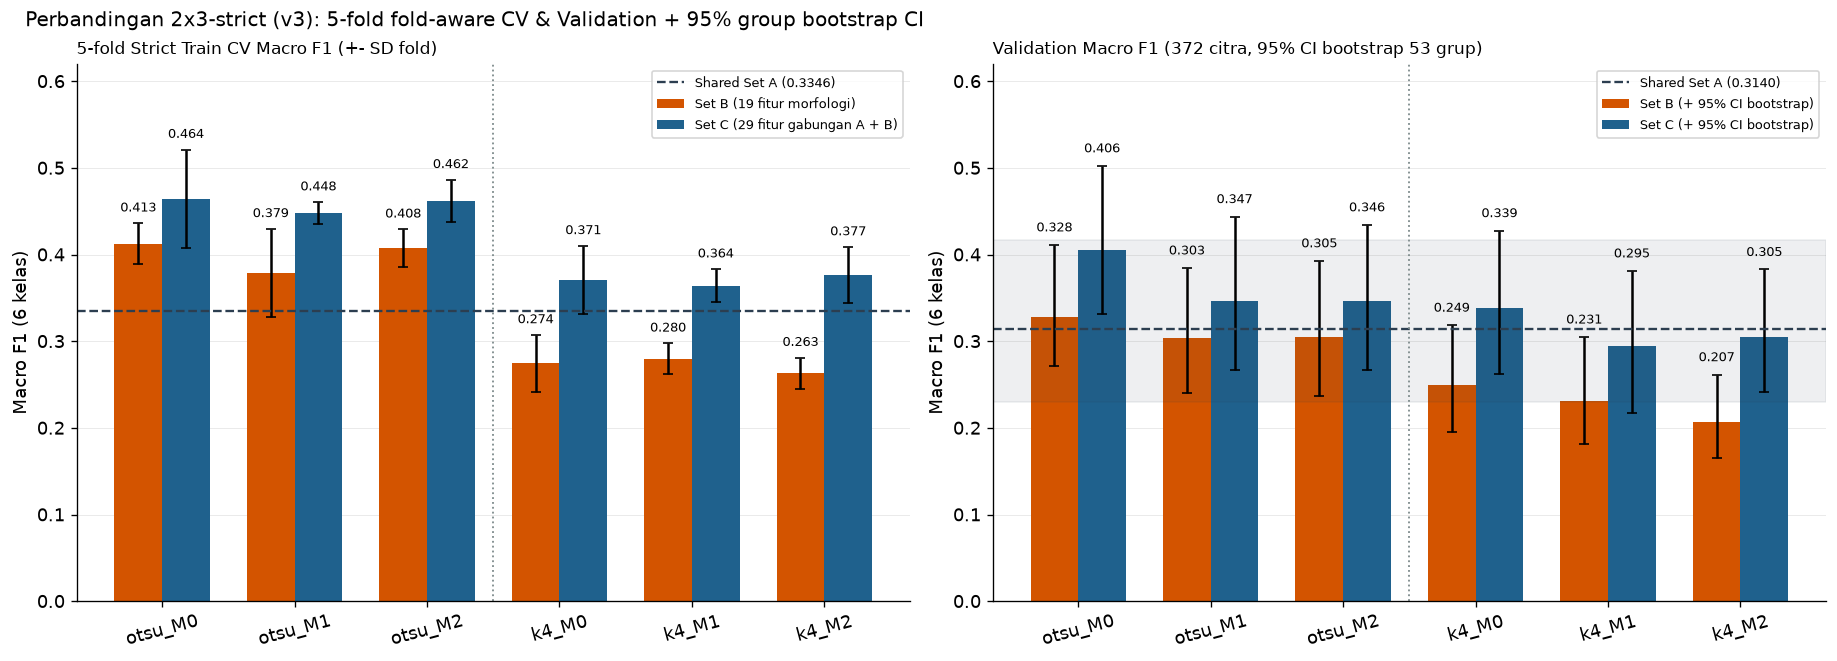

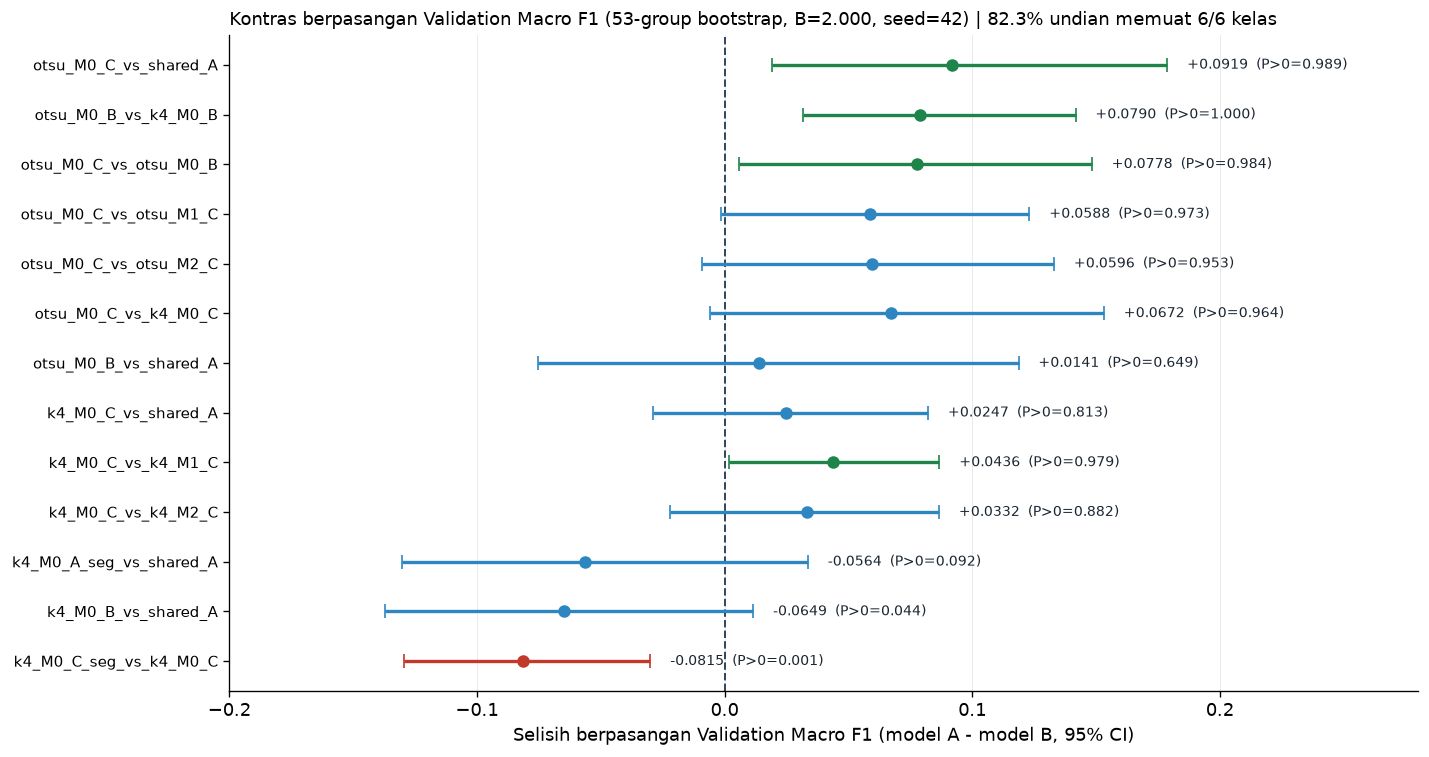

In [4]:
cv_sel_only = summary_df.loc[summary_df["model_variant"].eq("cv_selected")].copy()
def_only = summary_df.loc[summary_df["model_variant"].eq("default_rbf")].set_index(["method", "feature_set"])
cv_sel_only["default_rbf_val_macro_f1"] = [
    float(def_only.loc[(row["method"], row["feature_set"]), "val_macro_f1"])
    for _, row in cv_sel_only.iterrows()
]

display_cols = [
    "track",
    "method",
    "feature_set",
    "kernel",
    "class_weight",
    "C",
    "gamma",
    "cv_macro_f1",
    "cv_fold_macro_f1_mean",
    "cv_fold_macro_f1_std",
    "val_macro_f1",
    "val_macro_f1_ci95_low",
    "val_macro_f1_ci95_high",
    "val_balanced_accuracy",
    "val_accuracy",
    "default_rbf_val_macro_f1",
]
display(
    cv_sel_only[display_cols].style.format(
        {
            "C": "{:.1f}",
            "cv_macro_f1": "{:.4f}",
            "cv_fold_macro_f1_mean": "{:.4f}",
            "cv_fold_macro_f1_std": "{:.4f}",
            "val_macro_f1": "{:.4f}",
            "val_macro_f1_ci95_low": "{:.4f}",
            "val_macro_f1_ci95_high": "{:.4f}",
            "val_balanced_accuracy": "{:.4f}",
            "val_accuracy": "{:.4f}",
            "default_rbf_val_macro_f1": "{:.4f}",
        }
    )
)

strict_contrasts = contrasts_df.loc[contrasts_df["contrast_group"].eq("strict_2x3")].copy()
display(
    strict_contrasts[
        [
            "contrast_id",
            "val_macro_f1_a",
            "val_macro_f1_b",
            "delta_val_macro_f1",
            "delta_val_macro_f1_ci95_low",
            "delta_val_macro_f1_ci95_high",
            "prob_delta_macro_f1_gt_0",
            "delta_val_balanced_accuracy",
            "delta_val_bal_acc_ci95_low",
            "delta_val_bal_acc_ci95_high",
            "delta_val_accuracy",
            "delta_val_acc_ci95_low",
            "delta_val_acc_ci95_high",
        ]
    ].style.format(
        {
            "val_macro_f1_a": "{:.4f}",
            "val_macro_f1_b": "{:.4f}",
            "delta_val_macro_f1": "{:+.4f}",
            "delta_val_macro_f1_ci95_low": "{:+.4f}",
            "delta_val_macro_f1_ci95_high": "{:+.4f}",
            "prob_delta_macro_f1_gt_0": "{:.3f}",
            "delta_val_balanced_accuracy": "{:+.4f}",
            "delta_val_bal_acc_ci95_low": "{:+.4f}",
            "delta_val_bal_acc_ci95_high": "{:+.4f}",
            "delta_val_accuracy": "{:+.4f}",
            "delta_val_acc_ci95_low": "{:+.4f}",
            "delta_val_acc_ci95_high": "{:+.4f}",
        }
    )
)

# Figure 1: 2x3 strict CV (fold SD) vs Validation Macro-F1 (95% group bootstrap CI)
shared_a = cv_sel_only.loc[cv_sel_only["method"].eq(SHARED_APPEARANCE_METHOD)].iloc[0]
b_sub = cv_sel_only.loc[cv_sel_only["track"].eq("factorial_2x3") & cv_sel_only["feature_set"].eq("B")].set_index("method").loc[list(FEATURE_METHODS)]
c_sub = cv_sel_only.loc[cv_sel_only["track"].eq("factorial_2x3") & cv_sel_only["feature_set"].eq("C")].set_index("method").loc[list(FEATURE_METHODS)]

fig, axes = plt.subplots(1, 2, figsize=(15.2, 5.4), layout="constrained")
x = np.arange(len(FEATURE_METHODS))
w = 0.36

# Left panel: Strict CV Macro F1
b_cv = b_sub["cv_macro_f1"].to_numpy(dtype=float)
c_cv = c_sub["cv_macro_f1"].to_numpy(dtype=float)
c_cv_sd = c_sub["cv_fold_macro_f1_std"].to_numpy(dtype=float)
bars_b0 = axes[0].bar(x - w / 2, b_cv, width=w, yerr=b_sub["cv_fold_macro_f1_std"].to_numpy(dtype=float), capsize=2.8, color="#D35400", label="Set B (19 fitur morfologi)")
bars_c0 = axes[0].bar(x + w / 2, c_cv, width=w, yerr=c_cv_sd, capsize=2.8, color="#1F618D", label="Set C (29 fitur gabungan A + B)")
axes[0].axhline(float(shared_a["cv_macro_f1"]), color="#2C3E50", linestyle="--", linewidth=1.4, label=f"Shared Set A ({float(shared_a['cv_macro_f1']):.4f})")
for bar, val, err in zip(bars_b0, b_cv, b_sub["cv_fold_macro_f1_std"].to_numpy(dtype=float)):
    axes[0].text(bar.get_x() + bar.get_width() / 2.0, val + err + 0.010, f"{val:.3f}", ha="center", va="bottom", fontsize=7.5)
for bar, val, err in zip(bars_c0, c_cv, c_cv_sd):
    axes[0].text(bar.get_x() + bar.get_width() / 2.0, val + err + 0.010, f"{val:.3f}", ha="center", va="bottom", fontsize=7.5)
axes[0].axvline(2.5, color="#7F8C8D", linestyle=":", linewidth=1.1)
axes[0].set_xticks(x, list(FEATURE_METHODS), rotation=15)
axes[0].set_ylim(0.0, 0.62)
axes[0].set_ylabel("Macro F1 (6 kelas)")
axes[0].set_title("5-fold Strict Train CV Macro F1 (+- SD fold)", loc="left", fontsize=10.2)
axes[0].legend(frameon=True, fontsize=8.1, loc="upper right")
axes[0].grid(axis="y", color="#EAEAEA", linewidth=0.6)

# Right panel: Validation Macro F1 with 53-group 95% bootstrap CI
b_val = b_sub["val_macro_f1"].to_numpy(dtype=float)
b_err = np.vstack([b_val - b_sub["val_macro_f1_ci95_low"].to_numpy(dtype=float), b_sub["val_macro_f1_ci95_high"].to_numpy(dtype=float) - b_val])
c_val = c_sub["val_macro_f1"].to_numpy(dtype=float)
c_err = np.vstack([c_val - c_sub["val_macro_f1_ci95_low"].to_numpy(dtype=float), c_sub["val_macro_f1_ci95_high"].to_numpy(dtype=float) - c_val])
bars_b1 = axes[1].bar(x - w / 2, b_val, width=w, yerr=b_err, capsize=3.0, color="#D35400", label="Set B (+ 95% CI bootstrap)")
bars_c1 = axes[1].bar(x + w / 2, c_val, width=w, yerr=c_err, capsize=3.0, color="#1F618D", label="Set C (+ 95% CI bootstrap)")
axes[1].axhspan(float(shared_a["val_macro_f1_ci95_low"]), float(shared_a["val_macro_f1_ci95_high"]), color="#2C3E50", alpha=0.08)
axes[1].axhline(float(shared_a["val_macro_f1"]), color="#2C3E50", linestyle="--", linewidth=1.4, label=f"Shared Set A ({float(shared_a['val_macro_f1']):.4f})")
for bar, val, hi in zip(bars_b1, b_val, b_err[1]):
    axes[1].text(bar.get_x() + bar.get_width() / 2.0, val + hi + 0.012, f"{val:.3f}", ha="center", va="bottom", fontsize=7.5)
for bar, val, hi in zip(bars_c1, c_val, c_err[1]):
    axes[1].text(bar.get_x() + bar.get_width() / 2.0, val + hi + 0.012, f"{val:.3f}", ha="center", va="bottom", fontsize=7.5)
axes[1].axvline(2.5, color="#7F8C8D", linestyle=":", linewidth=1.1)
axes[1].set_xticks(x, list(FEATURE_METHODS), rotation=15)
axes[1].set_ylim(0.0, 0.62)
axes[1].set_ylabel("Macro F1 (6 kelas)")
axes[1].set_title("Validation Macro F1 (372 citra, 95% CI bootstrap 53 grup)", loc="left", fontsize=10.2)
axes[1].legend(frameon=True, fontsize=8.1, loc="upper right")
axes[1].grid(axis="y", color="#EAEAEA", linewidth=0.6)

fig.suptitle(
    "Perbandingan 2x3-strict (v3): 5-fold fold-aware CV & Validation + 95% group bootstrap CI",
    fontsize=12.0,
    x=0.01,
    ha="left",
)
finish_figure(
    fig,
    export_path=(ROOT / "reports/figures/07_2x3_classification_overview.png") if EXPORT_FIGURES else None,
)

# Figure 2: Paired validation bootstrap forest plot for key strict_2x3 contrasts
key_order = [
    "otsu_M0_C_vs_shared_A",
    "otsu_M0_B_vs_k4_M0_B",
    "otsu_M0_C_vs_otsu_M0_B",
    "otsu_M0_C_vs_otsu_M1_C",
    "otsu_M0_C_vs_otsu_M2_C",
    "otsu_M0_C_vs_k4_M0_C",
    "otsu_M0_B_vs_shared_A",
    "k4_M0_C_vs_shared_A",
    "k4_M0_C_vs_k4_M1_C",
    "k4_M0_C_vs_k4_M2_C",
    "k4_M0_A_seg_vs_shared_A",
    "k4_M0_B_vs_shared_A",
    "k4_M0_C_seg_vs_k4_M0_C",
]
sub_c = strict_contrasts.set_index("contrast_id").loc[key_order].iloc[::-1]
fig_fp, ax_fp = plt.subplots(figsize=(11.8, 6.2), layout="constrained")
y_pos = np.arange(len(sub_c))
deltas = sub_c["delta_val_macro_f1"].to_numpy(dtype=float)
lo_err = deltas - sub_c["delta_val_macro_f1_ci95_low"].to_numpy(dtype=float)
hi_err = sub_c["delta_val_macro_f1_ci95_high"].to_numpy(dtype=float) - deltas
p_gt0 = sub_c["prob_delta_macro_f1_gt_0"].to_numpy(dtype=float)

colors_fp = [
    "#1E8449" if (lo > 0) else ("#C0392B" if hi < 0 else "#2E86C1")
    for lo, hi in zip(sub_c["delta_val_macro_f1_ci95_low"], sub_c["delta_val_macro_f1_ci95_high"])
]
ax_fp.axvline(0.0, color="#34495E", linestyle="--", linewidth=1.2)
for yi, dv, le, he, col, pval in zip(y_pos, deltas, lo_err, hi_err, colors_fp, p_gt0):
    ax_fp.errorbar(dv, yi, xerr=[[le], [he]], fmt="o", color=col, ecolor=col, elinewidth=2.0, capsize=4.0, markersize=6.5)
    ax_fp.text(dv + he + 0.008, yi, f"{dv:+.4f}  (P>0={pval:.3f})", va="center", ha="left", fontsize=8.2, color="#1B2631")

ax_fp.set_yticks(y_pos, [f"{cid}" for cid in sub_c.index], fontsize=8.8)
ax_fp.set_xlim(-0.20, 0.28)
ax_fp.set_xlabel("Selisih berpasangan Validation Macro F1 (model A - model B, 95% CI)")
ax_fp.set_title(
    "Kontras berpasangan Validation Macro F1 (53-group bootstrap, B=2.000, seed=42) | 82.3% undian memuat 6/6 kelas",
    loc="left",
    fontsize=10.5,
)
ax_fp.grid(axis="x", color="#EAEAEA", linewidth=0.6)
finish_figure(
    fig_fp,
    export_path=(ROOT / "reports/figures/07_2x3_strict_paired_bootstrap_contrasts.png") if EXPORT_FIGURES else None,
)


### Temuan 3 — kontras inferensial utama di bawah `2x3-strict` + bootstrap 53 grup

- **`svm_otsu_M0_C` (`linear, C=3, none`) tetap peringkat #1 pada kedua tolok ukur:** `cv_macro_f1 = 0,4642` (`fold_mean = 0,4380 ± 0,0570`), **`val_macro_f1 = 0,4058`** (`95% CI [0,3316, 0,5025]`), `val_balanced_accuracy = 0,4016` (`[0,3344, 0,4962]`), `val_accuracy = 56,72%` (`[46,28%, 65,97%]`).
- **Tiga kesimpulan dengan *95% bootstrap CI* seluruhnya di atas nol ($P(\Delta > 0) \ge 98,4\%$):**
  1. `otsu_M0_C - shared_A` = **`+0,0919`** (`[+0,0190, +0,1788]`, $P(\Delta > 0) = 0,989$; *BalAcc* `+0,0808 [+0,0083, +0,1736]`): penggabungan fitur morfologi mentah Otsu meningkatkan Macro-F1 secara reliabel di atas warna/GLCM saja.
  2. `otsu_M0_B - k4_M0_B` = **`+0,0790`** (`[+0,0316, +0,1417]`, $P(\Delta > 0) = 0,9995$; *BalAcc* `+0,0991 [+0,0458, +0,1983]`): pada morfologi murni (Set B), Otsu mentah jauh mengungguli `k4_M0` (dan `k4_M0_B` sendiri tertinggal di bawah `Shared Set A` dengan `0,2490` vs `0,3140`).
  3. `otsu_M0_C - otsu_M0_B` = **`+0,0778`** (`[+0,0060, +0,1483]`, $P(\Delta > 0) = 0,984$; *Acc* `+13,17 pp`): menggabungkan *appearance* A dan morfologi B nyata lebih baik daripada morfologi Otsu saja.
- **Kontras antar-metode pada Set C:** `otsu_M0_C` unggul `+0,0672` atas `k4_M0_C` (`95% CI [-0,0060, +0,1532], P(>0) = 0,964`; akurasi `+12,10 pp [+4,15, +21,09 pp]`) dan `+0,0596` atas `otsu_M2_C` (`[-0,0091, +0,1330], P(>0) = 0,9525`; akurasi `+12,10 pp [+4,32, +20,00 pp]`). Kedua CI Macro-F1 sedikit menyentuh nol karena jumlah grup minoritas `val` yang kecil (`2` grup `Serrated adenoma`, `3` grup `Normal`).


## 4. Hubungan deskriptif kualitas segmentasi (`Dice` / `IoU`) vs klasifikasi hilir ($n=6$ konfigurasi)

Karena korelasi lintas **enam konfigurasi dependen ($n=6$)** yang dihitung pada citra validasi bersama tidak memenuhi asumsi uji sampel independen, metrik `Pearson r` dan `Spearman rho` di sini disajikan **secara eksplisit sebagai ringkasan besarnya asosiasi deskriptif (*descriptive magnitude summaries*)** tanpa klaim *p-value* konfirmatori.


,method,feature_set,seg_val_mean_category_dice,seg_val_mean_category_iou,train_val_mean_fg_fraction,train_val_mean_component_count,train_val_mean_edge_fg_fraction,kernel,class_weight,C,gamma,cv_macro_f1,val_macro_f1,val_macro_f1_ci95_low,val_macro_f1_ci95_high,val_balanced_accuracy,val_accuracy,delta_val_macro_f1_vs_shared_A,delta_val_macro_f1_C_minus_B
0,otsu_M0,B,0.7232,0.5788,0.5433,201.1,0.7967,rbf,balanced,10.0,0.01,0.4126,0.3280,0.2712,0.4113,0.3781,0.4355,+0.0141,+0.0000
1,otsu_M0,C,0.7232,0.5788,0.5433,201.1,0.7967,linear,none,3.0,scale,0.4642,0.4058,0.3316,0.5025,0.4016,0.5672,+0.0919,+0.0778
2,otsu_M1,B,0.7248,0.5811,0.5304,62.5,0.8120,rbf,balanced,10.0,0.01,0.3789,0.3033,0.2398,0.3847,0.3576,0.3817,-0.0106,+0.0000
3,otsu_M1,C,0.7248,0.5811,0.5304,62.5,0.8120,rbf,balanced,3.0,0.01,0.4481,0.3470,0.2669,0.4439,0.4171,0.4516,+0.0331,+0.0437
4,otsu_M2,B,0.7288,0.5886,0.5269,69.5,0.8536,rbf,balanced,10.0,0.01,0.4077,0.3055,0.2366,0.3929,0.3393,0.4113,-0.0085,+0.0000
5,otsu_M2,C,0.7288,0.5886,0.5269,69.5,0.8536,rbf,balanced,3.0,0.01,0.4622,0.3462,0.2666,0.4345,0.4240,0.4462,+0.0322,+0.0407
6,k4_M0,B,0.7761,0.6427,0.8527,26.4,0.9918,rbf,balanced,10.0,scale,0.2744,0.2490,0.1950,0.3187,0.2790,0.3333,-0.0649,+0.0000
7,k4_M0,C,0.7761,0.6427,0.8527,26.4,0.9918,rbf,balanced,3.0,scale,0.3707,0.3386,0.2624,0.4277,0.4018,0.4462,+0.0247,+0.0896
8,k4_M1,B,0.7760,0.6426,0.8513,5.2,0.9932,rbf,balanced,10.0,0.1,0.2797,0.2311,0.1810,0.3050,0.2829,0.3280,-0.0829,+0.0000
9,k4_M1,C,0.7760,0.6426,0.8513,5.2,0.9932,rbf,balanced,10.0,0.01,0.3643,0.2951,0.2174,0.3813,0.3489,0.3898,-0.0189,+0.0640


Catatan metodologis manifest: Computed across n=6 dependent configurations on shared validation images; treat as descriptive magnitude summaries rather than confirmatory hypothesis tests.


,feature_set,seg_metric,cls_metric,n_configs,pearson_r_desc,spearman_rho_desc
0,B,val_cat_dice,cv_macro_f1,6,-0.9799,-0.7714
1,B,val_cat_dice,val_macro_f1,6,-0.9478,-0.7143
2,B,val_cat_dice,val_balanced_accuracy,6,-0.9066,-0.8286
3,B,val_cat_dice,val_accuracy,6,-0.9188,-0.7143
4,B,val_cat_iou,cv_macro_f1,6,-0.9764,-0.7714
5,B,val_cat_iou,val_macro_f1,6,-0.9502,-0.7143
6,B,val_cat_iou,val_balanced_accuracy,6,-0.9129,-0.8286
7,B,val_cat_iou,val_accuracy,6,-0.9186,-0.7143
8,C,val_cat_dice,cv_macro_f1,6,-0.9876,-0.8857
9,C,val_cat_dice,val_macro_f1,6,-0.7706,-0.8286


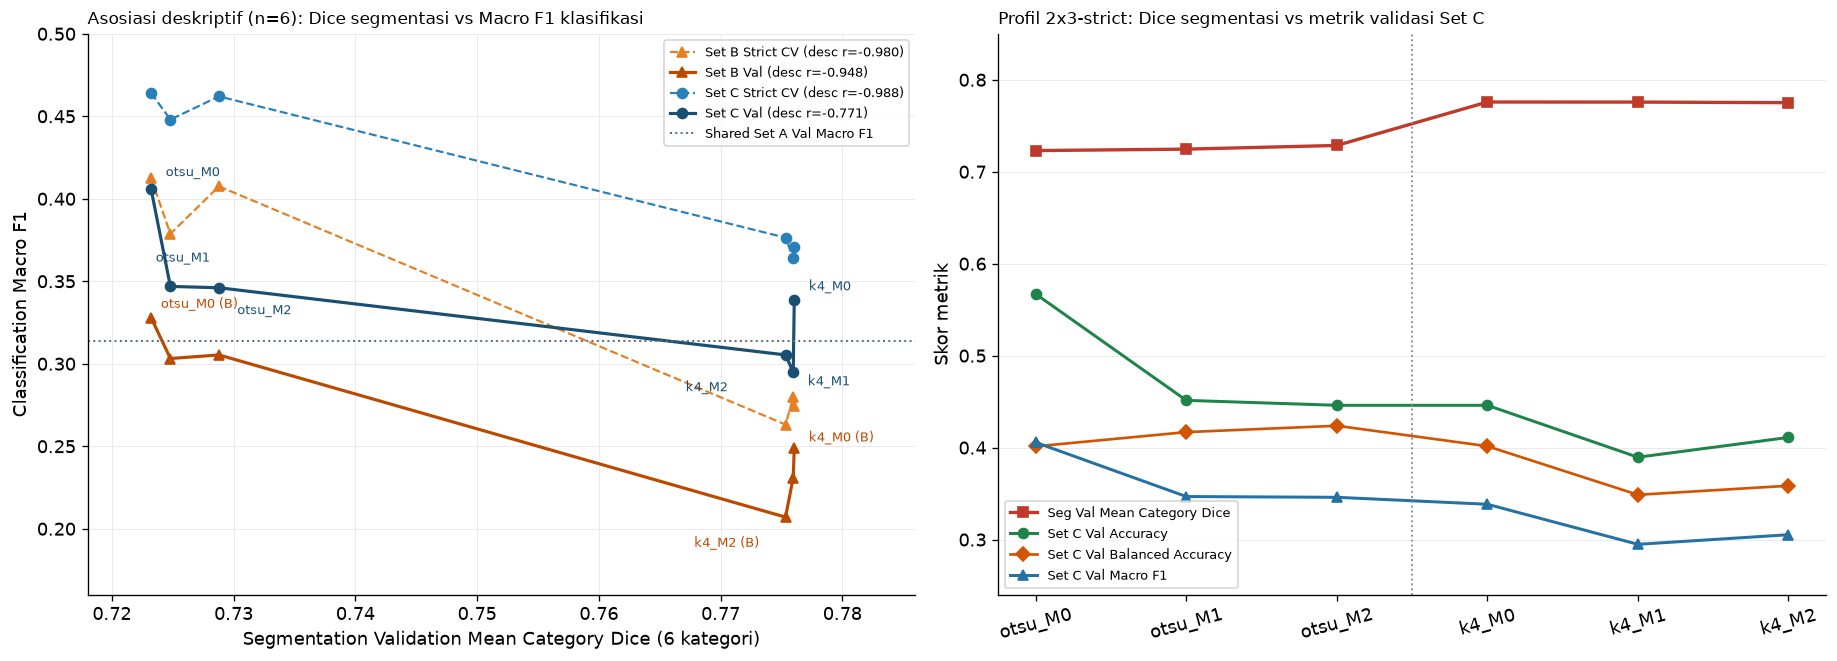

In [5]:
seg_cls_show = seg_cls_df[
    [
        "method",
        "feature_set",
        "seg_val_mean_category_dice",
        "seg_val_mean_category_iou",
        "train_val_mean_fg_fraction",
        "train_val_mean_component_count",
        "train_val_zero_perim_pct" if "train_val_zero_perim_pct" in seg_cls_df.columns else "train_val_mean_edge_fg_fraction",
        "kernel",
        "class_weight",
        "C",
        "gamma",
        "cv_macro_f1",
        "val_macro_f1",
        "val_macro_f1_ci95_low",
        "val_macro_f1_ci95_high",
        "val_balanced_accuracy",
        "val_accuracy",
        "delta_val_macro_f1_vs_shared_A",
        "delta_val_macro_f1_C_minus_B",
    ]
].copy()

fmt_seg = {
    "seg_val_mean_category_dice": "{:.4f}",
    "seg_val_mean_category_iou": "{:.4f}",
    "train_val_mean_fg_fraction": "{:.4f}",
    "train_val_mean_component_count": "{:.1f}",
    "train_val_mean_edge_fg_fraction": "{:.4f}",
    "C": "{:.1f}",
    "cv_macro_f1": "{:.4f}",
    "val_macro_f1": "{:.4f}",
    "val_macro_f1_ci95_low": "{:.4f}",
    "val_macro_f1_ci95_high": "{:.4f}",
    "val_balanced_accuracy": "{:.4f}",
    "val_accuracy": "{:.4f}",
    "delta_val_macro_f1_vs_shared_A": "{:+.4f}",
    "delta_val_macro_f1_C_minus_B": "{:+.4f}",
}
display(seg_cls_show.style.format(fmt_seg))

# Descriptive-only correlations (explicitly omitting p-value column to prevent n=6 overclaiming)
corr_meta = cls_manifest["correlations_descriptive_only_n6"]
print("Catatan metodologis manifest:", corr_meta["warning"])
corr_payload = corr_meta["values"]
corr_rows = []
for fset in ("B", "C"):
    for seg_prefix in ("seg_val_mean_category_dice", "seg_val_mean_category_iou"):
        for pair_key, stats_dict in corr_payload[fset].items():
            if pair_key.startswith(seg_prefix + "_vs_"):
                cls_metric = pair_key.replace(seg_prefix + "_vs_", "")
                corr_rows.append(
                    {
                        "feature_set": fset,
                        "seg_metric": seg_prefix.replace("seg_val_mean_category_", "val_cat_"),
                        "cls_metric": cls_metric,
                        "n_configs": 6,
                        "pearson_r_desc": stats_dict["pearson_r"],
                        "spearman_rho_desc": stats_dict["spearman_rho"],
                    }
                )
display(pd.DataFrame(corr_rows).style.format({"pearson_r_desc": "{:+.4f}", "spearman_rho_desc": "{:+.4f}"}))

fig_sc, axes_sc = plt.subplots(1, 2, figsize=(15.2, 5.4), layout="constrained")
for fset, marker, color_cv, color_val in [
    ("B", "^", "#E67E22", "#BA4A00"),
    ("C", "o", "#2980B9", "#1B4F72"),
]:
    sub = seg_cls_df.loc[seg_cls_df["feature_set"].eq(fset)].sort_values("seg_val_mean_category_dice")
    xd = sub["seg_val_mean_category_dice"].to_numpy(dtype=float)
    y_cv = sub["cv_macro_f1"].to_numpy(dtype=float)
    y_va = sub["val_macro_f1"].to_numpy(dtype=float)

    r_cv = corr_payload[fset]["seg_val_mean_category_dice_vs_cv_macro_f1"]["pearson_r"]
    r_va = corr_payload[fset]["seg_val_mean_category_dice_vs_val_macro_f1"]["pearson_r"]

    axes_sc[0].plot(xd, y_cv, marker=marker, linestyle="--", linewidth=1.3, color=color_cv, label=f"Set {fset} Strict CV (desc r={r_cv:+.3f})")
    axes_sc[0].plot(xd, y_va, marker=marker, linestyle="-", linewidth=1.9, color=color_val, label=f"Set {fset} Val (desc r={r_va:+.3f})")

    if fset == "C":
        offsets_c = {
            "otsu_M0": (0.0012, 0.008),
            "otsu_M1": (-0.0012, 0.015),
            "otsu_M2": (0.0015, -0.016),
            "k4_M0": (0.0012, 0.006),
            "k4_M1": (0.0012, -0.008),
            "k4_M2": (-0.0082, -0.022),
        }
        for _, row in sub.iterrows():
            dx, dy = offsets_c.get(str(row["method"]), (0.0005, 0.008))
            axes_sc[0].annotate(
                str(row["method"]),
                (float(row["seg_val_mean_category_dice"]) + dx, float(row["val_macro_f1"]) + dy),
                fontsize=8.0,
                color=color_val,
            )
    else:
        offsets_b = {
            "otsu_M0": (0.0008, 0.006),
            "k4_M0": (0.0012, 0.004),
            "k4_M2": (-0.0075, -0.018),
        }
        for _, row in sub.iterrows():
            m_str = str(row["method"])
            if m_str in offsets_b:
                dx, dy = offsets_b[m_str]
                axes_sc[0].annotate(
                    f"{m_str} (B)",
                    (float(row["seg_val_mean_category_dice"]) + dx, float(row["val_macro_f1"]) + dy),
                    fontsize=7.6,
                    color=color_val,
                )

axes_sc[0].axhline(float(shared_a["val_macro_f1"]), color="#5D6D7E", linestyle=":", linewidth=1.2, label="Shared Set A Val Macro F1")
axes_sc[0].set_xlabel("Segmentation Validation Mean Category Dice (6 kategori)")
axes_sc[0].set_ylabel("Classification Macro F1")
axes_sc[0].set_title("Asosiasi deskriptif (n=6): Dice segmentasi vs Macro F1 klasifikasi", loc="left", fontsize=10.1)
axes_sc[0].set_ylim(0.16, 0.50)
axes_sc[0].set_xlim(0.718, 0.786)
axes_sc[0].legend(frameon=True, fontsize=7.6, loc="upper right")
axes_sc[0].grid(color="#EAEAEA", linewidth=0.6)

pos = np.arange(len(FEATURE_METHODS))
c_ordered = seg_cls_df.loc[seg_cls_df["feature_set"].eq("C")].set_index("method").loc[list(FEATURE_METHODS)]
axes_sc[1].plot(pos, c_ordered["seg_val_mean_category_dice"], marker="s", linewidth=2.0, color="#C0392B", label="Seg Val Mean Category Dice")
axes_sc[1].plot(pos, c_ordered["val_accuracy"], marker="o", linewidth=1.8, color="#1E8449", label="Set C Val Accuracy")
axes_sc[1].plot(pos, c_ordered["val_balanced_accuracy"], marker="D", linewidth=1.6, color="#D35400", label="Set C Val Balanced Accuracy")
axes_sc[1].plot(pos, c_ordered["val_macro_f1"], marker="^", linewidth=1.8, color="#2471A3", label="Set C Val Macro F1")
axes_sc[1].axvline(2.5, color="#7F8C8D", linestyle=":", linewidth=1.1)
axes_sc[1].set_xticks(pos, list(FEATURE_METHODS), rotation=15)
axes_sc[1].set_ylim(0.24, 0.85)
axes_sc[1].set_ylabel("Skor metrik")
axes_sc[1].set_title("Profil 2x3-strict: Dice segmentasi vs metrik validasi Set C", loc="left", fontsize=10.1)
axes_sc[1].legend(frameon=True, fontsize=8.0, loc="lower left")
axes_sc[1].grid(axis="y", color="#EAEAEA", linewidth=0.6)

finish_figure(
    fig_sc,
    export_path=(ROOT / "reports/figures/07_2x3_seg_dice_vs_classification.png") if EXPORT_FIGURES else None,
)


### Temuan 4 — mengapa Dice segmentasi tinggi (`k4`) justru berasosiasi terbalik dengan klasifikasi hilir

- **Pola deskriptif lintas $n=6$ konfigurasi sangat konsisten arah negatifnya:**
  - **Set B (morfologi murni):** Pearson deskriptif `r = −0,9799` (CV Macro-F1), `r = −0,9478` (Val Macro-F1), Spearman `rho = −0,7714` dan `−0,7143`.
  - **Set C (gabungan 29 fitur):** `r = −0,9876` (`rho = −0,8857`) di CV Macro-F1 dan `r = −0,7706` (`rho = −0,8286`) di Val Macro-F1.
- **Interpretasi mekanis:** `k4` mengejar cakupan *region-level* luas (`85%–87%` luas bidang citra; `mask_edge_foreground_fraction > 0,99`) sehingga meraih Dice tinggi (`0,775–0,776`) namun melebur pulau epitel–stroma menjadi beberapa lembaran besar. Sebaliknya, Otsu (`53%–54%` luas citra, Dice `0,723–0,729`) mempertahankan fragmentasi inti sel/kompleks epitel gelap (`201` komponen rata-rata pada `otsu_M0`) yang memisahkan kelas-kelas displasia dan adenokarsinoma jauh lebih baik.


## 5. *Validation-blind* `class_weight` *trade-off*, kalibrasi pasca-seleksi, dan linimasa `v1` vs `v2` vs `v3`

Karena `svm_2x3_strict_grid_results.csv` tidak menyimpan skor `val` untuk 32 kandidat hiperparameter, sel ini membedakan dengan tegas dua tahap analisis:
1. **Tahap CV internal murni (`grid_df`, `0` kolom `val_*`):** membandingkan kandidat terbaik `class_weight='none'` vs `'balanced'` pada *5-fold Strict CV*.
2. **Tahap pasca-seleksi (`summary_df`, 1 model terpilih vs `default_rbf` `none, C=1`):** memeriksa bagaimana pembobotan `balanced` yang unggul tipis di CV pada `otsu_M1_C`, `otsu_M2_C`, dan seluruh `k4` cenderung mengorbankan presisi dan *Val Macro-F1* di hadapan kelas minoritas validasi (`8` citra *Serrated adenoma*, `10` *Normal*), sekaligus menyandingkan perubahan protokol `v1` $\rightarrow$ `v2` $\rightarrow$ `v3`.


,method,class_weight,kernel,C,gamma,cv_macro_f1,cv_fold_macro_f1_mean,cv_balanced_accuracy,cv_accuracy,is_selected_best
6,otsu_M0,balanced,rbf,3.0,0.01,0.4587,0.4544,0.5217,0.5127,False
7,otsu_M0,none,linear,3.0,scale,0.4642,0.4380,0.4428,0.5818,True
8,otsu_M1,balanced,rbf,3.0,0.01,0.4481,0.4428,0.5076,0.5127,True
9,otsu_M1,none,rbf,10.0,scale,0.4221,0.4138,0.4097,0.5876,False
10,otsu_M2,balanced,rbf,3.0,0.01,0.4622,0.4647,0.5190,0.5498,True
11,otsu_M2,none,linear,1.0,scale,0.4541,0.4474,0.4389,0.6150,False
0,k4_M0,balanced,rbf,3.0,scale,0.3707,0.3679,0.3917,0.4769,True
1,k4_M0,none,linear,3.0,scale,0.3700,0.3556,0.3522,0.5049,False
2,k4_M1,balanced,rbf,10.0,0.01,0.3643,0.3655,0.3946,0.4515,True
3,k4_M1,none,rbf,3.0,scale,0.3566,0.3539,0.3503,0.5537,False


,method_set_C,v1_spec (val-tuned k4_M0),v1_val_f1,v2_spec (fixed-up CV),v2_cv_f1,v2_val_f1,v3_spec (strict CV),v3_cv_f1,v3_val_f1
0,otsu_M0,rbf none C=10 g=0.01,0.3976,linear none C=3 g=scale,0.4642,0.4058,linear none C=3 g=scale,0.4642,0.4058
1,otsu_M2,rbf none C=10 g=0.01,0.4587,rbf balanced C=3 g=0.01,0.4622,0.3462,rbf balanced C=3 g=0.01,0.4622,0.3462
2,k4_M0,rbf none C=10 g=0.01,0.3625,rbf balanced C=10 g=0.01,0.3774,0.3362,rbf balanced C=3 g=scale,0.3707,0.3386
3,k4_M1,rbf none C=10 g=0.01,0.3311,linear none C=10 g=scale,0.3571,0.3189,rbf balanced C=10 g=0.01,0.3643,0.2951


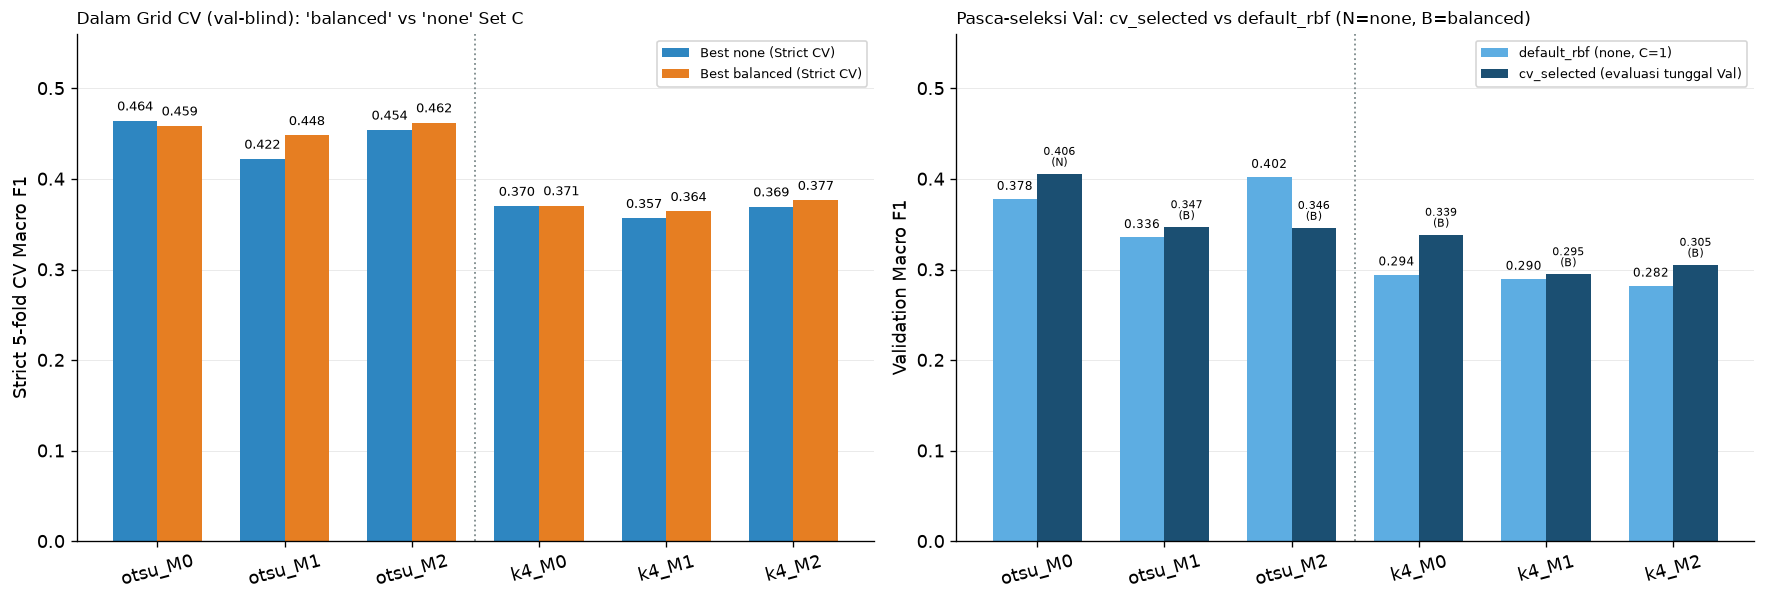

In [6]:
fact_grid = grid_df.loc[grid_df["track"].eq("factorial_2x3") & grid_df["feature_set"].eq("C")].copy()
# Sort using the deterministic cv_selection_key_for_svm rule (purely CV metrics, zero val info)
fact_grid["_sel_key"] = [cv_selection_key_for_svm(rec) for rec in fact_grid.to_dict("records")]
cw_cv_best = (
    fact_grid.sort_values("_sel_key", ascending=False)
    .groupby(["method", "class_weight"], observed=True)
    .first()
    .reset_index()
)
cw_cv_best["method"] = pd.Categorical(cw_cv_best["method"], categories=list(FEATURE_METHODS), ordered=True)
cw_cv_best = cw_cv_best.sort_values(["method", "class_weight"])

display(
    cw_cv_best[
        [
            "method",
            "class_weight",
            "kernel",
            "C",
            "gamma",
            "cv_macro_f1",
            "cv_fold_macro_f1_mean",
            "cv_balanced_accuracy",
            "cv_accuracy",
            "is_selected_best",
        ]
    ].style.format(
        {
            "C": "{:.1f}",
            "cv_macro_f1": "{:.4f}",
            "cv_fold_macro_f1_mean": "{:.4f}",
            "cv_balanced_accuracy": "{:.4f}",
            "cv_accuracy": "{:.4f}",
        }
    )
)

# Three-layer lineage table (v1 val-tuned vs v2 fixed-upstream CV vs v3 strict fold-aware & val-blind)
legacy_comp = pd.read_csv(protected_files["v1_cls_comp"])
legacy_c = legacy_comp.loc[
    legacy_comp["feature_set"].eq("C") & legacy_comp["spec_variant"].eq("primary_tuned_spec")
].set_index("method")
v2_sum = pd.read_csv(protected_files["v2_cls_summary"])
v2_c = v2_sum.loc[v2_sum["model_variant"].eq("cv_selected") & v2_sum["feature_set"].eq("C")].set_index("method")
v3_c = cv_sel_only.loc[cv_sel_only["feature_set"].eq("C") & cv_sel_only["track"].eq("factorial_2x3")].set_index("method")

lineage_rows = []
for m in ("otsu_M0", "otsu_M2", "k4_M0", "k4_M1"):
    lineage_rows.append(
        {
            "method_set_C": m,
            "v1_spec (val-tuned k4_M0)": f"{legacy_c.loc[m, 'kernel']} {legacy_c.loc[m, 'class_weight']} C={legacy_c.loc[m, 'C']:g} g={legacy_c.loc[m, 'gamma']}",
            "v1_val_f1": float(legacy_c.loc[m, "val_macro_f1"]),
            "v2_spec (fixed-up CV)": f"{v2_c.loc[m, 'kernel']} {v2_c.loc[m, 'class_weight']} C={v2_c.loc[m, 'C']:g} g={v2_c.loc[m, 'gamma']}",
            "v2_cv_f1": float(v2_c.loc[m, "cv_macro_f1"]),
            "v2_val_f1": float(v2_c.loc[m, "val_macro_f1"]),
            "v3_spec (strict CV)": f"{v3_c.loc[m, 'kernel']} {v3_c.loc[m, 'class_weight']} C={v3_c.loc[m, 'C']:g} g={v3_c.loc[m, 'gamma']}",
            "v3_cv_f1": float(v3_c.loc[m, "cv_macro_f1"]),
            "v3_val_f1": float(v3_c.loc[m, "val_macro_f1"]),
        }
    )
display(
    pd.DataFrame(lineage_rows).style.format(
        {
            "v1_val_f1": "{:.4f}",
            "v2_cv_f1": "{:.4f}",
            "v2_val_f1": "{:.4f}",
            "v3_cv_f1": "{:.4f}",
            "v3_val_f1": "{:.4f}",
        }
    )
)

# Plot: Left = Strict CV Grid none vs balanced (CV Macro-F1); Right = Post-selection Val default_rbf (none) vs cv_selected
fig_cw, axes_cw = plt.subplots(1, 2, figsize=(14.6, 4.9), layout="constrained")
none_c = cw_cv_best.loc[cw_cv_best["class_weight"].eq("none")].set_index("method").loc[list(FEATURE_METHODS)]
bal_c = cw_cv_best.loc[cw_cv_best["class_weight"].eq("balanced")].set_index("method").loc[list(FEATURE_METHODS)]
px = np.arange(len(FEATURE_METHODS))
bw = 0.35

v_none = none_c["cv_macro_f1"].to_numpy(dtype=float)
v_bal = bal_c["cv_macro_f1"].to_numpy(dtype=float)
b1 = axes_cw[0].bar(px - bw / 2, v_none, width=bw, color="#2E86C1", label="Best none (Strict CV)")
b2 = axes_cw[0].bar(px + bw / 2, v_bal, width=bw, color="#E67E22", label="Best balanced (Strict CV)")
for b, v in zip(b1, v_none):
    axes_cw[0].text(b.get_x() + b.get_width() / 2.0, v + 0.008, f"{v:.3f}", ha="center", va="bottom", fontsize=7.5)
for b, v in zip(b2, v_bal):
    axes_cw[0].text(b.get_x() + b.get_width() / 2.0, v + 0.008, f"{v:.3f}", ha="center", va="bottom", fontsize=7.5)
axes_cw[0].axvline(2.5, color="#7F8C8D", linestyle=":", linewidth=1.1)
axes_cw[0].set_xticks(px, list(FEATURE_METHODS), rotation=15)
axes_cw[0].set_ylim(0.0, 0.56)
axes_cw[0].set_ylabel("Strict 5-fold CV Macro F1")
axes_cw[0].set_title("Dalam Grid CV (val-blind): 'balanced' vs 'none' Set C", loc="left", fontsize=10.0)
axes_cw[0].legend(frameon=True, fontsize=8.1, loc="upper right")
axes_cw[0].grid(axis="y", color="#EAEAEA", linewidth=0.6)

c_sel = cv_sel_only.loc[cv_sel_only["track"].eq("factorial_2x3") & cv_sel_only["feature_set"].eq("C")].set_index("method").loc[list(FEATURE_METHODS)]
c_def = summary_df.loc[summary_df["model_variant"].eq("default_rbf") & summary_df["track"].eq("factorial_2x3") & summary_df["feature_set"].eq("C")].set_index("method").loc[list(FEATURE_METHODS)]
v_def_va = c_def["val_macro_f1"].to_numpy(dtype=float)
v_sel_va = c_sel["val_macro_f1"].to_numpy(dtype=float)
b3 = axes_cw[1].bar(px - bw / 2, v_def_va, width=bw, color="#5DADE2", label="default_rbf (none, C=1)")
b4 = axes_cw[1].bar(px + bw / 2, v_sel_va, width=bw, color="#1B4F72", label="cv_selected (evaluasi tunggal Val)")
for b, v in zip(b3, v_def_va):
    axes_cw[1].text(b.get_x() + b.get_width() / 2.0, v + 0.007, f"{v:.3f}", ha="center", va="bottom", fontsize=7.0)
for b, v, cw in zip(b4, v_sel_va, c_sel["class_weight"]):
    tag = "(N)" if cw == "none" else "(B)"
    axes_cw[1].text(b.get_x() + b.get_width() / 2.0, v + 0.007, f"{v:.3f}\n{tag}", ha="center", va="bottom", fontsize=6.9, linespacing=0.95)
axes_cw[1].axvline(2.5, color="#7F8C8D", linestyle=":", linewidth=1.1)
axes_cw[1].set_xticks(px, list(FEATURE_METHODS), rotation=15)
axes_cw[1].set_ylim(0.0, 0.56)
axes_cw[1].set_ylabel("Validation Macro F1")
axes_cw[1].set_title("Pasca-seleksi Val: cv_selected vs default_rbf (N=none, B=balanced)", loc="left", fontsize=10.0)
axes_cw[1].legend(frameon=True, fontsize=8.1, loc="upper right")
axes_cw[1].grid(axis="y", color="#EAEAEA", linewidth=0.6)

finish_figure(
    fig_cw,
    export_path=(ROOT / "reports/figures/07_2x3_cw_tradeoff.png") if EXPORT_FIGURES else None,
)


### Temuan 5 — koreksi ilusi peringkat `v1` dan dinamika *overfitting* pembobotan minoritas

- **Mengapa peringkat `otsu_M2_C` turun dari `v1` (`0,4587`) ke `v2`/`v3` (`0,3462`)?**
  - Pada `v1`, pemilihan spesifikasi didominasi skor `val` pada `k4_M0_C` (`rbf, none, C=10, g=0,01`) lalu spesifikasi `none` tersebut disalin ke `otsu_M2`.
  - Ketika seleksi dipaksa *validation-blind* pada *5-fold CV*, `balanced` unggul tipis pada `otsu_M2_C` (`0,4622` vs `0,4541`), tetapi di validasi menghasilkan banyak *false positive* ke kelas langka sehingga Val Macro-F1 turun menjadi `0,3462` (kendati `default_rbf` `none` pada `otsu_M2_C` mencatat `0,4021` di post-selection *summary*).
  - **`otsu_M0_C` sudah memilih `linear, none, C=3` langsung dari CV (`0,4642` > best `balanced` `0,4469`)**, sehingga menjadi satu-satunya pemenang yang kokoh baik pada *5-fold CV* maupun evaluasi tunggal `val` (`0,4058`).


## 6. Metrik per kategori dan *confusion matrices* lintas 6 konfigurasi (`Set C`), `Shared Set A`, dan `Set B` terbaik (`v3`)

Sel ini menampilkan tabel **per-category F1** serta matriks konfusi validasi (`372` citra) yang seluruhnya bersumber dari prediksi ketat `v3` (`svm_2x3_strict_val_predictions.csv`).


category,Adenocarcinoma,High-grade IN,Low-grade IN,Normal,Polyp,Serrated adenoma,Macro F1 (Val)
model_id,,,,,,,
svm_shared_A,0.4649,0.0667,0.4964,0.1739,0.6818,0.0000,0.3140
svm_otsu_M0_B,0.3465,0.2647,0.5429,0.1111,0.6404,0.0625,0.3280
svm_otsu_M0_C,0.5512,0.2759,0.5593,0.0952,0.7312,0.2222,0.4058
svm_otsu_M1_C,0.3469,0.2182,0.5650,0.1887,0.6744,0.0889,0.3470
svm_otsu_M2_C,0.4098,0.1639,0.5320,0.1887,0.6628,0.1200,0.3462
svm_k4_M0_C,0.3768,0.1923,0.4978,0.2143,0.6901,0.0606,0.3386
svm_k4_M1_C,0.3246,0.1270,0.4752,0.1695,0.6364,0.0377,0.2951
svm_k4_M2_C,0.3317,0.1176,0.4815,0.1538,0.6667,0.0816,0.3055
svm_k4_M0_A_seg,0.2011,0.0938,0.4242,0.1587,0.6303,0.0370,0.2575


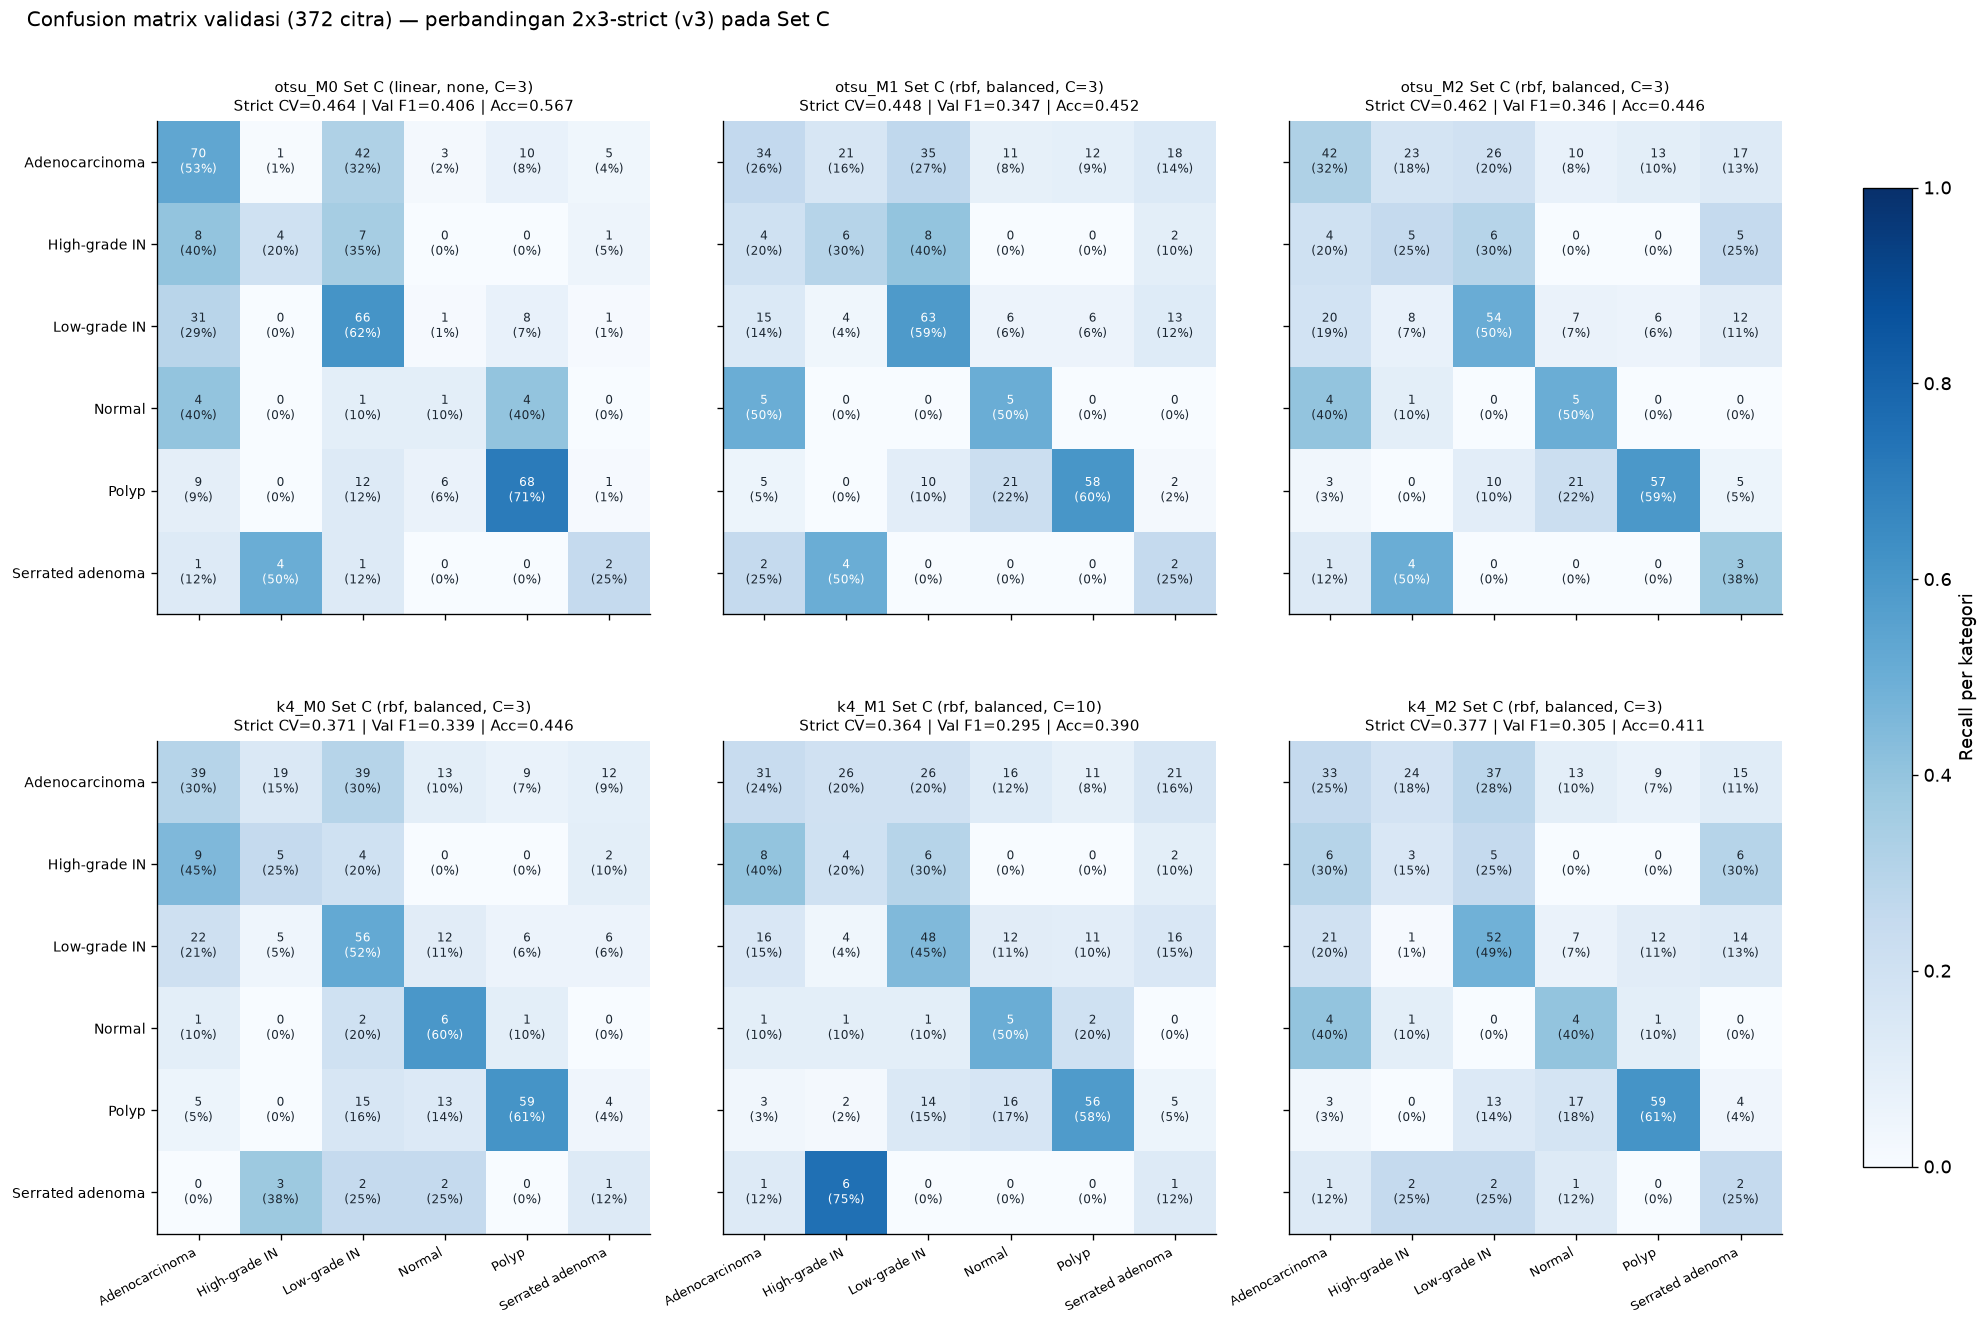

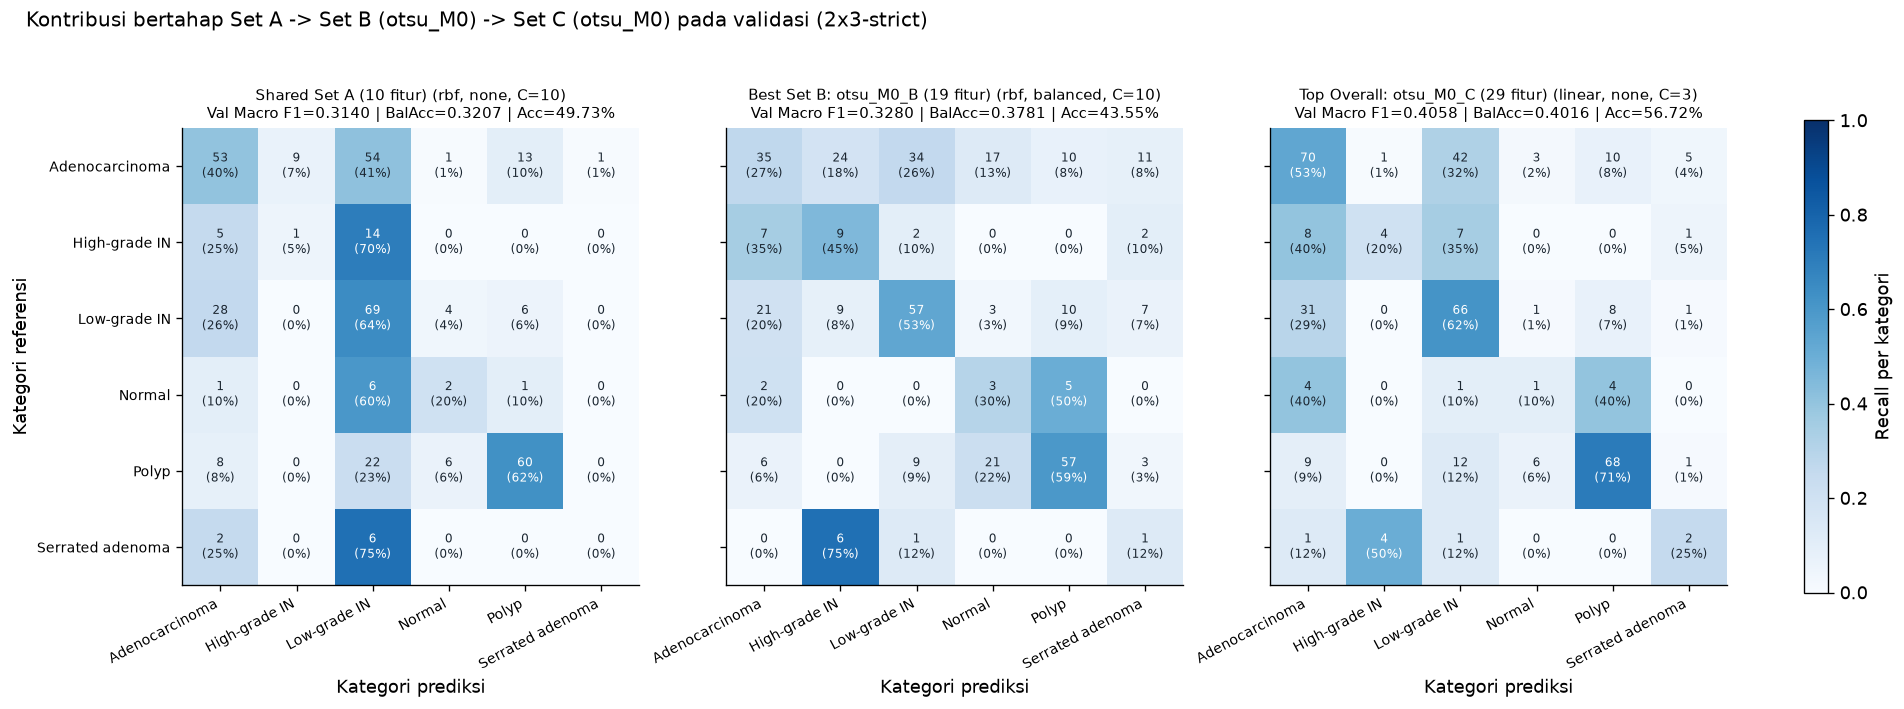

In [7]:
cat_cv_sel = per_cat_df.loc[per_cat_df["model_variant"].eq("cv_selected")].copy()
f1_pivot = cat_cv_sel.pivot(index="model_id", columns="category", values="f1")[list(EXPECTED_CATEGORIES)]
order_models = [
    "svm_shared_A",
    "svm_otsu_M0_B",
    "svm_otsu_M0_C",
    "svm_otsu_M1_C",
    "svm_otsu_M2_C",
    "svm_k4_M0_C",
    "svm_k4_M1_C",
    "svm_k4_M2_C",
    "svm_k4_M0_A_seg",
    "svm_k4_M0_C_seg",
]
f1_table = f1_pivot.reindex(order_models)
f1_table["Macro F1 (Val)"] = f1_table.mean(axis=1)
display(f1_table.style.format("{:.4f}"))

# 1. Complete 2x3 grid of confusion matrices for Set C (v3 strict)
category_labels = list(EXPECTED_CATEGORIES)
fig_cm2x3, axes_2x3 = plt.subplots(2, 3, figsize=(16.5, 11.2), layout="constrained")
sel_preds = val_pred_df.loc[val_pred_df["model_variant"].eq("cv_selected")].copy()

for idx, (ax, method) in enumerate(zip(axes_2x3.ravel(), FEATURE_METHODS)):
    sub_p = sel_preds.loc[sel_preds["method"].eq(method) & sel_preds["feature_set"].eq("C")].sort_values("sample_id")
    cm_cnt = confusion_matrix_table(sub_p["category"], sub_p["predicted_category"], normalize=None)
    cm_nrm = confusion_matrix_table(sub_p["category"], sub_p["predicted_category"], normalize="true")
    m_info = v3_c.loc[method]
    im = ax.imshow(cm_nrm.to_numpy(), cmap="Blues", vmin=0.0, vmax=1.0)
    ax.set_xticks(np.arange(6), category_labels if idx >= 3 else [], rotation=28, ha="right", fontsize=8.0)
    ax.set_yticks(np.arange(6), category_labels if idx in (0, 3) else [], fontsize=8.2)
    ax.set_title(
        f"{method} Set C ({m_info['kernel']}, {m_info['class_weight']}, C={m_info['C']:g})\n"
        f"Strict CV={m_info['cv_macro_f1']:.3f} | Val F1={m_info['val_macro_f1']:.3f} | Acc={m_info['val_accuracy']:.3f}",
        fontsize=9.2,
    )
    ax.grid(False)
    for r in range(6):
        for c in range(6):
            cnt = int(cm_cnt.iat[r, c])
            pct = 100.0 * float(cm_nrm.iat[r, c])
            ax.text(
                c,
                r,
                f"{cnt}\n({pct:.0f}%)",
                ha="center",
                va="center",
                fontsize=7.2,
                color="white" if pct >= 50.0 else "#1B2631",
            )

fig_cm2x3.colorbar(im, ax=axes_2x3, shrink=0.82, label="Recall per kategori")
fig_cm2x3.get_layout_engine().set(rect=(0.0, 0.0, 1.0, 0.95), h_pad=0.14, hspace=0.06)
fig_cm2x3.suptitle(
    "Confusion matrix validasi (372 citra) — perbandingan 2x3-strict (v3) pada Set C",
    fontsize=12.0,
    x=0.01,
    y=0.985,
    ha="left",
)
finish_figure(
    fig_cm2x3,
    export_path=(ROOT / "reports/figures/07_2x3_confusion_matrices_set_C.png") if EXPORT_FIGURES else None,
)

# 2. Side-by-side comparison: Shared Set A vs Best Set B (otsu_M0_B) vs Best Set C (otsu_M0_C)
sum_by_id = cv_sel_only.set_index("model_id")
fig_abc, axes_abc = plt.subplots(1, 3, figsize=(15.8, 5.8), layout="constrained")
for ax, m_id, prefix_lbl in zip(
    axes_abc,
    ["svm_shared_A", "svm_otsu_M0_B", "svm_otsu_M0_C"],
    ["Shared Set A (10 fitur)", "Best Set B: otsu_M0_B (19 fitur)", "Top Overall: otsu_M0_C (29 fitur)"],
):
    info = sum_by_id.loc[m_id]
    sub_p = sel_preds.loc[sel_preds["model_id"].eq(m_id)].sort_values("sample_id")
    cm_cnt = confusion_matrix_table(sub_p["category"], sub_p["predicted_category"], normalize=None)
    cm_nrm = confusion_matrix_table(sub_p["category"], sub_p["predicted_category"], normalize="true")
    im2 = ax.imshow(cm_nrm.to_numpy(), cmap="Blues", vmin=0.0, vmax=1.0)
    ax.set_xticks(np.arange(6), category_labels, rotation=28, ha="right", fontsize=8.2)
    ax.set_yticks(np.arange(6), category_labels if m_id == "svm_shared_A" else [], fontsize=8.4)
    if m_id == "svm_shared_A":
        ax.set_ylabel("Kategori referensi")
    ax.set_xlabel("Kategori prediksi")
    ax.set_title(
        f"{prefix_lbl} ({info['kernel']}, {info['class_weight']}, C={info['C']:g})\n"
        f"Val Macro F1={info['val_macro_f1']:.4f} | BalAcc={info['val_balanced_accuracy']:.4f} | Acc={info['val_accuracy']:.2%}",
        fontsize=8.9,
    )
    ax.grid(False)
    for r in range(6):
        for c in range(6):
            cnt = int(cm_cnt.iat[r, c])
            pct = 100.0 * float(cm_nrm.iat[r, c])
            ax.text(
                c,
                r,
                f"{cnt}\n({pct:.0f}%)",
                ha="center",
                va="center",
                fontsize=7.3,
                color="white" if pct >= 50.0 else "#1B2631",
            )

fig_abc.colorbar(im2, ax=axes_abc, shrink=0.82, label="Recall per kategori")
fig_abc.get_layout_engine().set(rect=(0.0, 0.0, 1.0, 0.91))
fig_abc.suptitle(
    "Kontribusi bertahap Set A -> Set B (otsu_M0) -> Set C (otsu_M0) pada validasi (2x3-strict)",
    fontsize=11.8,
    x=0.01,
    y=0.985,
    ha="left",
)
finish_figure(
    fig_abc,
    export_path=(ROOT / "reports/figures/07_2x3_confusion_matrices_shared_A_best_B_best_C.png") if EXPORT_FIGURES else None,
)


### Temuan 6 — pemisahan per kategori dan sensitivitas `A_seg` / `C_seg` di bawah `v3`

- **Peningkatan merata pada `svm_otsu_M0_C`:** dibanding `Shared Set A`, F1 validasi naik pada `Adenocarcinoma` (`0,4649 -> 0,5512`), `High-grade IN` (`0,0667 -> 0,2759`), `Low-grade IN` (`0,4964 -> 0,5593`), `Polyp` (`0,6818 -> 0,7312`), dan memulihkan `Serrated adenoma` (`0,0000 -> 0,2222`).
- **Sensitivitas `A_seg`/`C_seg` pada `k4_M0`:** di bawah `2x3-strict`, `k4_M0_C_seg` mencapai `cv_macro_f1 = 0,3897` namun turun di validasi menjadi `0,2572` (`val_accuracy = 35,75%`), tertinggal `-0,0815 [95% CI -0,1296, -0,0300], P(>0) = 0,001` di bawah `k4_M0_C` unmasked (`0,3386`). Pemasking tekstur/warna ke masker lebar `k4_M0` tidak menguntungkan ketika latar stroma dihilangkan.


## 7. Reproduksi & verifikasi paritas ke-15 artefak model JSON portabel (`models/cv_2x3_strict/`) dan demarkasi `test`

Sel ini memastikan ke-15 model `cv_selected` (`models/cv_2x3_strict/*.json`) cocok penuh (`<= 1e-10`) terhadap `sklearn.svm.SVC` dari `train` kanonik penuh serta memverifikasi bahwa seluruh artefak historis `v1`, `v2`, dan `results/test/` tetap tidak berubah.


In [8]:
train_seg, val_seg, _ = load_classification_feature_frame(ROOT, method=PRIMARY_METHOD, segmented=True)
method_dev_frames = {m: load_classification_feature_frame(ROOT, method=m, segmented=False)[:2] for m in FEATURE_METHODS}

parity_rows = []
for art_rel in cls_manifest["exported_model_files"]:
    art_path = ROOT / art_rel
    artifact = load_svm_artifact(art_path)
    assert artifact.get("cv_protocol") == "5fold_stratified_group_kfold_strict_fold_aware_upstream"
    method = str(artifact["segmentation_method"])
    set_name = str(artifact["feature_set"])
    cols = feature_columns_for_set(set_name)

    if method == SHARED_APPEARANCE_METHOD:
        tr_f, va_f = train_app, val_app
    elif set_name in ("A_seg", "C_seg"):
        tr_f, va_f = train_seg, val_seg
    else:
        tr_f, va_f = method_dev_frames[method]

    X_tr_raw = tr_f[list(cols)].to_numpy(dtype=np.float64)
    y_tr = tr_f["category"].to_numpy(dtype=object)
    X_va_raw = va_f[list(cols)].to_numpy(dtype=np.float64)
    y_va = va_f["category"].to_numpy(dtype=object)

    sc_re = fit_standard_scaler(X_tr_raw, cols)
    np.testing.assert_allclose(sc_re["mean"], artifact["scaler"]["mean"], rtol=0.0, atol=1e-12)
    np.testing.assert_allclose(sc_re["scale"], artifact["scaler"]["scale"], rtol=0.0, atol=1e-12)

    clf = fit_svm_model(
        apply_standard_scaler(X_tr_raw, sc_re),
        y_tr,
        kernel=str(artifact["kernel"]),
        C=float(artifact["C"]),
        gamma=artifact["gamma_param"],
        class_weight=str(artifact["class_weight"]),
    )
    parity = verify_svm_artifact_parity(X_va_raw, clf, artifact, atol=DECISION_PARITY_ATOL)
    pred_labels, _, _ = predict_from_svm_artifact(X_va_raw, artifact)
    re_metrics = classification_metrics(y_va, pred_labels)
    for k, expected in artifact["validation_metrics"].items():
        assert abs(re_metrics[k] - float(expected)) < 1e-12

    parity_rows.append(
        {
            "model_id": artifact["model_id"],
            "method": method,
            "feature_set": set_name,
            "kernel": artifact["kernel"],
            "class_weight": artifact["class_weight"],
            "C": float(artifact["C"]),
            "gamma": artifact["gamma_param"],
            "max_abs_ovo_diff": float(parity["max_abs_decision_diff"]),
            "exact_label_match": bool(parity["exact_prediction_match"]),
            "val_macro_f1": float(re_metrics["macro_f1"]),
        }
    )

parity_df = pd.DataFrame(parity_rows)
display(
    parity_df.style.format(
        {
            "C": "{:.1f}",
            "max_abs_ovo_diff": "{:.3e}",
            "val_macro_f1": "{:.4f}",
        }
    )
)
assert parity_df["max_abs_ovo_diff"].max() <= DECISION_PARITY_ATOL
assert parity_df["exact_label_match"].all()

input_hashes_after = {name: sha256_bytes(path) for name, path in protected_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak yang dilindungi berubah saat notebook dieksekusi."
print(
    f"Selesai: ke-15 model v3 (models/cv_2x3_strict/) lulus paritas (max_diff={parity_df['max_abs_ovo_diff'].max():.3e}); "
    "seluruh artefak split, v1, Stage 08 historis, v2, dan v3 tetap byte-identical; 0 citra test disentuh."
)


,model_id,method,feature_set,kernel,class_weight,C,gamma,max_abs_ovo_diff,exact_label_match,val_macro_f1
0,svm_shared_A,shared_appearance,A,rbf,none,10.0,scale,3.275e-12,True,0.3140
1,svm_otsu_M0_B,otsu_M0,B,rbf,balanced,10.0,0.01,4.888e-12,True,0.3280
2,svm_otsu_M0_C,otsu_M0,C,linear,none,3.0,scale,6.179e-12,True,0.4058
3,svm_otsu_M1_B,otsu_M1,B,rbf,balanced,10.0,0.01,4.634e-12,True,0.3033
4,svm_otsu_M1_C,otsu_M1,C,rbf,balanced,3.0,0.01,1.121e-12,True,0.3470
5,svm_otsu_M2_B,otsu_M2,B,rbf,balanced,10.0,0.01,3.461e-12,True,0.3055
6,svm_otsu_M2_C,otsu_M2,C,rbf,balanced,3.0,0.01,8.362e-13,True,0.3462
7,svm_k4_M0_B,k4_M0,B,rbf,balanced,10.0,scale,1.997e-12,True,0.2490
8,svm_k4_M0_C,k4_M0,C,rbf,balanced,3.0,scale,4.254e-13,True,0.3386
9,svm_k4_M1_B,k4_M1,B,rbf,balanced,10.0,0.1,1.100e-12,True,0.2311


Selesai: ke-15 model v3 (models/cv_2x3_strict/) lulus paritas (max_diff=6.179e-12); seluruh artefak split, v1, Stage 08 historis, v2, dan v3 tetap byte-identical; 0 citra test disentuh.
